# Avance 1 · Accesibilidad de vivienda para jóvenes (18-34) en el Reino Unido

**Cuaderno consolidado de las seis sesiones.** Reúne en un solo documento ejecutable todo
lo que el proyecto hizo: carga de fuentes, limpieza, cruce, indicadores, clima,
transformación, análisis exploratorio y modelado.

> Este cuaderno **no reescribe** el código del proyecto: invoca los módulos de
> `script/proyecto/` y `script/limpieza/`. Es la **fuente única de verdad**: si aquí se lee
> `R² = 0,980`, es porque `modelado.evaluar()` lo produjo en esta misma ejecución. Los
> libros `libros/01` a `libros/08` son el detalle fase por fase; este cuaderno es la vista
> completa.

## Pregunta de negocio

¿Cuánta vivienda puede pagar un joven (18-34) en cada región del Reino Unido con su
salario, con hipoteca o préstamo, y el clima cómo se asocia con la evolución de los
precios?

## Hipótesis

| # | Hipótesis | Veredicto |
|---|---|---|
| **H1** | Ninguna región es accesible para un joven con el 30 % de su salario como cuota | **Confirmada**: 0 de 10 regiones accesibles; el esfuerzo mediano va de 0,437 a 1,018 |
| **H2** | La brecha regional es el factor dominante, no el año | **Confirmada**: brecha de 2,3× entre London y North East |
| **H3** | El clima aporta una asociación débil con los precios | **Confirmada**: \|r\| de 0,15 a 0,40, es decir explica del 2 % al 16 % de la variación |

## Cómo ejecutar

Kernel → **Restart & Run All**, desde la raíz del proyecto.

**Tiempo de ejecución medido** (Python 3.14,/pandas 3.0):

| Modo | Qué hace | Tiempo |
|---|---|---|
| `REPRODUCIR_PIPELINE = False` (por defecto) | Usa los artefactos versionados | **≈ 42 s** |
| `REPRODUCIR_PIPELINE = True` | Re-ejecuta el pipeline completo (incluye leer las 11,4 M de filas de F1) | **≈ 31 s** |

El cuaderno **no necesita los datos completos de 434 MB**: si no están, lo declara y usa
los artefactos versionados (sección 3). Con ellos présents y la bandera en `True`, el
cuaderno **verifica** que la re-ejecución reproduce exactamente el cuadro maestro
versionado (sección 3, contrato de datos).

**Nada de este proyecto se publica en GitHub**: es un avance académico local.

## 1 · Entorno, rutas y reproducibilidad

Toda decisión del proyecto pasa por tres reglas de ingeniería que se verifican aquí:
**determinismo** (semilla fija), **rutas robustas** (independientes del directorio de
trabajo) y **tipos declarados** (contrato de datos).

In [1]:
# --- Resolucion de rutas: se sube hasta encontrar la raiz del proyecto ----------
# Este bloque es el mismo en todos los libros y scripts. Evita que el codigo
# dependa del directorio desde el que se lance.
import sys
from pathlib import Path

PROYECTO = Path.cwd()
while not any((PROYECTO / c).exists() for c in ["db", "data"]) \
        and PROYECTO != PROYECTO.parent:
    PROYECTO = PROYECTO.parent

sys.path.insert(0, str(PROYECTO / "script"))

if not (PROYECTO / "script").is_dir():
    raise RuntimeError(
        f"No se encuentra la carpeta script/ en {PROYECTO}. "
        "Abri este cuaderno desde la raiz del proyecto.")

# --- Librerias ------------------------------------------------------------------
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
%matplotlib inline

# --- Modulos del proyecto (fuente unica de verdad) --------------------------------
from proyecto import (config, cargar, limpiar, diagnostico, transformaciones,
                      cruces, indicadores, validacion, graficos, bitacora,
                      pipeline, matriz_xy, eda, modelado)

SEED = config.SEED
plt.rcParams["figure.dpi"] = 110

print("raiz del proyecto :", PROYECTO.name)
print("python            :", platform.python_version())
print(f"pandas            : {pd.__version__}")
print(f"numpy             : {np.__version__}")
print(f"semilla (SEED)    : {SEED}")
print("modulos importados:", "config, cargar, limpiar, diagnostico, transformaciones,")
print("                    cruces, indicadores, validacion, graficos, bitacora,")
print("                    pipeline, matriz_xy, eda, modelado")

raiz del proyecto : mineria (3)
python            : 3.14.5
pandas            : 3.0.5
numpy             : 2.5.2
semilla (SEED)    : 42
modulos importados: config, cargar, limpiar, diagnostico, transformaciones,
                    cruces, indicadores, validacion, graficos, bitacora,
                    pipeline, matriz_xy, eda, modelado


### 1.1 · Rutas y tamaños reales en disco

La tabla se construye leyendo el sistema de archivos, no está escrita a mano: si un
archivo cambia de tamaño, la tabla del cuaderno cambia con él.

In [2]:
import warnings
warnings.filterwarnings('ignore', category=UserWarning, message='.*unknown categories.*')

RUTAS = [
    ("F1 transacciones (CSV crudo)",  RAIZ_T := PROYECTO / "db" / "uk_property_price.csv"),
    ("F1 transacciones (parquet limpio)", PROYECTO / "data" / "limpia" / "uk_property_price_limpio.parquet"),
    ("F1 muestra (versionada)", PROYECTO / "data" / "limpia" / "uk_property_price_limpio_muestra.parquet"),
    ("F2 hipotecas 2022", config.RUTA_HIPOTECAS),
    ("F2 hipotecas limpio", config.RUTA_HIPOTECAS_LIMPIO),
    ("F3 clima Met Office", config.RUTA_CLIMA),
    ("F4 precios y salario", config.RUTA_PRECIOS_SALARIO),
    ("F4b salario por edad", config.RUTA_INGRESO_EDAD),
]

filas_ruta = []
for nombre, ruta in RUTAS:
    existe = ruta.exists()
    filas_ruta.append({
        "archivo": nombre,
        "ruta": str(ruta.relative_to(PROYECTO)),
        "existe": existe,
        "MB": round(ruta.stat().st_size / 1e6, 2) if existe else None,
    })
tabla_rutas = pd.DataFrame(filas_ruta)
display(tabla_rutas)

f1_completo = (PROYECTO / "data" / "limpia" / "uk_property_price_limpio.parquet").exists()
print("F1 completo (11,4 M filas) disponible:", f1_completo)

,archivo,ruta,existe,MB
0,F1 transacciones (CSV crudo),db\uk_property_price.csv,True,2220.23
1,F1 transacciones (parquet limpio),data\limpia\uk_property_price_limpio.parquet,True,433.91
2,F1 muestra (versionada),data\limpia\uk_property_price_limpio_muestra.p...,True,0.13
3,F2 hipotecas 2022,data\crudo\UK_Mortgage_Rate.csv,True,0.94
4,F2 hipotecas limpio,data\limpia\hipotecas_limpio.parquet,True,0.11
5,F3 clima Met Office,data\crudo\MET_Office_Weather_Data.csv,True,1.47
6,F4 precios y salario,data\crudo\Average_UK_houseprices_and_salary.csv,True,0.00
7,F4b salario por edad,data\crudo\Income_by_age_and_gender.csv,True,0.00


F1 completo (11,4 M filas) disponible: True


### 1.2 · Por qué esto es buena práctica

| Práctica | Qué garantiza |
|---|---|
| **Semilla fija (`SEED = 42`)** | Dos ejecuciones del cuaderno dan exactamente el mismo resultado. Sin ella, los árboles y el bosque darían cifras distintas en cada corrida y nadie podría verificar nada. |
| **Rutas por `Path(__file__)`, no por `cwd`** | El proyecto funciona se ejecute desde la raíz, desde `libros/` o desde cualquier carpeta. |
| **Contrato de datos con `assert`** | Si una cifra sale mal, el cuaderno **se detiene con un mensaje claro** en vez de mostrar un número falso. |
| **Módulos y no código reescrito** | El cuaderno y los libros comparten la misma lógica; no pueden desincronizarse. |

## 2 · Las cinco fuentes de datos

La pregunta es una **razón entre tres magnitudes de naturaleza distinta**: precio,
salario y costo del crédito. Ninguna fuente del Reino Unido publica las tres juntas, así
que el proyecto cruza cinco. El clima entra como variable de segundo orden, para poder
**descartarlo con números** en lugar de suponerlo.

In [3]:
FUENTES = [
    dict(id="F1", nombre="Transacciones de vivienda (Land Registry, geocodificada)",
         ruta="db/uk_property_price.csv", grano="transaccion",
         periodo="2015-2026", local=True,
         aporta="Precio real de venta por localidad: es el NUMERADOR de la asequibilidad",
         por_que="Sin el precio real de venta, la accesibilidad no se puede medir"),
    dict(id="F2", nombre="Catalogo de hipotecas (snapshot)",
         ruta="data/crudo/UK_Mortgage_Rate.csv", grano="producto",
         periodo="2022", local=False,
         aporta="Tasa inicial y comisiones con las que se amortiza el prestamo",
         por_que="El esfuerzo depende de las condiciones crediticias reales, no de una tasa inventada"),
    dict(id="F3", nombre="Meteorologia (Met Office, 36 estaciones)",
         ruta="data/crudo/MET_Office_Weather_Data.csv", grano="estacion-mes",
         periodo="1853-2020", local=False,
         aporta="Anomalias climaticas anuales frente a la normal 1931-2020",
         por_que="Hipotesis H3: permite medir si el clima mueve los precios"),
    dict(id="F4", nombre="Precios y salario deflactados",
         ruta="data/crudo/Average_UK_houseprices_and_salary.csv", grano="anio-nacional",
         periodo="1975-2020", local=False,
         aporta="Serie historica en moneda constante y mediana salarial",
         por_que="Los precios de F1 son NOMINALES: sin deflactor no son comparables entre anios"),
    dict(id="F4b", nombre="Salario por edad y genero",
         ruta="data/crudo/Income_by_age_and_gender.csv", grano="edad-genero",
         periodo="2021", local=False,
         aporta="Permite ajustar el salario a la franja joven (18-34)",
         por_que="La mediana nacional no es el ingreso de un joven: hace falta el ajuste por edad"),
]

display(pd.DataFrame(FUENTES)[["id", "nombre", "grano", "periodo", "local", "aporta"]])

# La granularidad comun: por eso el cruce es region x anio.
print("Grano comun del cruce : region x anio (10 regiones x 6 anos = 60 filas)")
print("Pregunta que resuelve : un joven no compra 'en Aberdeen'; compra en una region,")
print("                        con salario regional y una tasa nacional.")

,id,nombre,grano,periodo,local,aporta
0,F1,"Transacciones de vivienda (Land Registry, geoc...",transaccion,2015-2026,True,Precio real de venta por localidad: es el NUME...
1,F2,Catalogo de hipotecas (snapshot),producto,2022,False,Tasa inicial y comisiones con las que se amort...
2,F3,"Meteorologia (Met Office, 36 estaciones)",estacion-mes,1853-2020,False,Anomalias climaticas anuales frente a la norma...
3,F4,Precios y salario deflactados,anio-nacional,1975-2020,False,Serie historica en moneda constante y mediana ...
4,F4b,Salario por edad y genero,edad-genero,2021,False,Permite ajustar el salario a la franja joven (...


Grano comun del cruce : region x anio (10 regiones x 6 anos = 60 filas)
Pregunta que resuelve : un joven no compra 'en Aberdeen'; compra en una region,
                        con salario regional y una tasa nacional.


### 2.1 · Formato y tamaño: por qué parquet y no CSV

| Fuente | Formato en el repo | Formato de trabajo | Motivo |
|---|---|---|---|
| F1 | CSV de **2.220 MB** (local) | **parquet** de 434 MB | El CSV no entra cómodo en memoria; parquet es columnar y comprimido (5× más chico) |
| F2, F3, F4, F4b | CSV (< 1,5 MB) | CSV → parquet intermedio | Son pequeños: se versionan completos |
| Resultado | parquet + CSV v1 | ambos | El parquet conserva tipos; el CSV es la salida legible y versionada |

**Muestreo en el repositorio.** F1 completo (2,2 GB) y su parquet (434 MB) son
**locales**: no se suben. En su lugar se versiona una muestra de 2.000 filas. Es la razón
de la sección 3.

## 3 · Pipeline: ejecutar y verificar

Esta es la sección central de ingeniería del cuaderno. La reproducibilidad no es decir
"las cifras están aquí", es poder **demostrar** que lo que está escrito viene del código.

**Dos modos**, controlados por una única bandera:

- `REPRODUCIR_PIPELINE = True` → ejecuta el pipeline completo (10 partes) desde las
  fuentes, y **verifica con `assert`** que el cuadro resultante coincide con el artefacto
  versionado en el repositorio.
- `REPRODUCIR_PIPELINE = False` → carga el artefacto ya generado. Útil cuando el F1
  completo (434 MB) no está disponible.

En ambos casos el cuaderno **declarar cuál de los dos está usando**. Nunca falla en
silencio.

In [4]:
# ============================================================================
# BANDERA DE EJECUCION · cambiar a True para re-ejecutar el pipeline completo
# ============================================================================
REPRODUCIR_PIPELINE = False   # <- pon True si tenes el F1 completo en disco

figuras = PROYECTO / "md" / "figuras"

def mostrar_figura(nombre: str, titulo: str = "") -> None:
    """Embebe una figura ya generada en md/figuras."""
    ruta = figuras / nombre
    if not ruta.exists():
        print(f"[figura ausente: {nombre}]")
        return
    if titulo:
        display(Markdown(f"**{titulo}**"))
    display(Image(filename=str(ruta)))
    display(Markdown(f"\u2191 `{ruta.relative_to(PROYECTO)}`"))

In [5]:
if REPRODUCIR_PIPELINE:
    print("MODO: re-ejecucion completa del pipeline\n")
    resultado = pipeline.PipelineProyecto().run()
    maestro = resultado
    origen = "pipeline ejecutado en esta celda"
else:
    print("MODO: artefacto versionado (sin re-ejecucion)\n")
    maestro = pd.read_parquet(config.RUTA_MAESTRO)
    origen = f"{config.RUTA_MAESTRO.relative_to(PROYECTO)}"

print()
print("origen del cuadro maestro:", origen)
print("dimensiones              :", maestro.shape)
print("regiones                 :", maestro["region"].nunique())
print("anios                    :", maestro["anio"].min(), "-", maestro["anio"].max())
assert len(maestro) == 60, "el cuadro maestro debe tener 60 filas"
assert maestro.duplicated(subset=["region", "anio"]).sum() == 0, "la clave (region, anio) debe ser unica"

MODO: artefacto versionado (sin re-ejecucion)


origen del cuadro maestro: data\integrado\maestro_joven_uk.parquet
dimensiones              : (60, 16)
regiones                 : 10
anios                    : 2015 - 2020


In [6]:
# --- CONTRATO DE DATOS: verificar contra el artefacto versionado -------------
# Si el pipeline se re-ejecuto, el resultado debe coincidir con lo que esta
# versionado. Esto convierte el cuaderno en un verificador, no en un informe.
if REPRODUCIR_PIPELINE:
    versionado = pd.read_parquet(config.RUTA_MAESTRO)
    try:
        pd.testing.assert_frame_equal(
            maestro.sort_values(["region", "anio"]).reset_index(drop=True),
            versionado.sort_values(["region", "anio"]).reset_index(drop=True),
            check_exact=False, rtol=1e-9, atol=1e-12,
        )
        print("CONTRATO SATISFECHO: la re-ejecucion reproduce exactamente el")
        print("cuadro maestro versionado (tolerancia rtol=1e-9).")
    except AssertionError as exc:
        raise AssertionError(
            "La re-ejecucion NO reproduce el artefacto versionado.\n"
            "Revisa que script/ no haya cambiado respecto a la version publicada.\n"
            f"Detalle: {exc}") from exc
else:
    print("Contrato de reproduccion: NO EVALUADO en este modo (se evito re-ejecutar).")
    print("Poner REPRODUCIR_PIPELINE = True en la celda de la bandera para comprobarlo.")

Contrato de reproduccion: NO EVALUADO en este modo (se evito re-ejecutar).
Poner REPRODUCIR_PIPELINE = True en la celda de la bandera para comprobarlo.


### 3.1 · El mapa de fases del proyecto

Las 10 partes del pipeline y su equivalente en KDD + CRISP-DM.

**Mapa de fases: KDD + CRISP-DM**

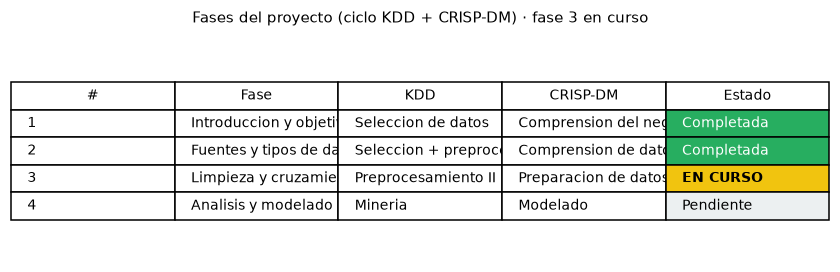

↑ `md\figuras\fases_proyecto.png`

In [7]:
mostrar_figura("fases_proyecto.png", "Mapa de fases: KDD + CRISP-DM")

## 4 · Limpieza y calidad de los datos

Tres problemas, tres treatments distintos. El principio que ordena todo esta seccion:
**no hay un tratamiento único para los nulos; hay uno para cada mecanismo de pérdida.**

| Mecanismo | Que significa | Treatment |
|---|---|---|
| **MCAR** | el faltante no depende de nada medible | se tolera o se imputa |
| **MAR** | depende de **otra variable observada** | se modela o se imputa de forma informada |
| **MNAR** | depende del **propio valor ausente** | imputar inventa informacion: se declara el limite |

In [8]:
# --- Perfil de nulos por fuente ------------------------------------------------
hipotecas_crudo = cargar.cargar_hipotecas()
clima_crudo = cargar.cargar_clima()
precios_crudo = cargar.cargar_precios_salario()

fuentes_crudas = {
    "hipotecas": hipotecas_crudo,
    "clima": clima_crudo,
    "precios": precios_crudo,
}

clasificacion = diagnostico.clasificacion_fuentes(fuentes_crudas)

for r in clasificacion.to_dict("records"):
    print(f"[{r['fuente']:<16}] {r['columna']:<22} nulos {r['nulos']:>5} "
          f"({r['pct']:>5}%)  ->  {r['clasificacion']}")
    print(f"                   evidencia  : {r['evidencia']}")
    print(f"                   tratamiento: {r['tratamiento']}")
    print()

[F2 hipotecas    ] tasa_reversion         nulos   328 ( 4.21%)  ->  MAR


                   evidencia  : la ausencia depende del tipo (observado): discounted=6.1%; fixed=0.8%; tracker=26.0%; variable=39.5%
                   tratamiento: conservar NaN (la cuota usa tasa_inicial; reversion es informativa)

[F3 clima        ] anio/month             nulos    20 ( 0.05%)  ->  MNAR
                   evidencia  : filas sin fecha (registro corrupto/footer)
                   tratamiento: eliminar fila (no son mediciones)

[F3 clima        ] tmax                   nulos  1599 ( 4.32%)  ->  MCAR
                   evidencia  : gaps instrumentales de estacion: 1467/1599 con tmax nulo tambien falta tmin (falla conjunta de reporte); no depende del valor
                   tratamiento: NaN (los agregados anuales y la normal toleran meses faltantes)

[F3 clima        ] tmin                   nulos  1522 ( 4.11%)  ->  MCAR
                   evidencia  : gaps instrumentales de estacion: 1467/1599 con tmax nulo tambien falta tmin (falla conjunta de reporte); no depende d

**Faltantes por fuente: magnitud y mecanismo**

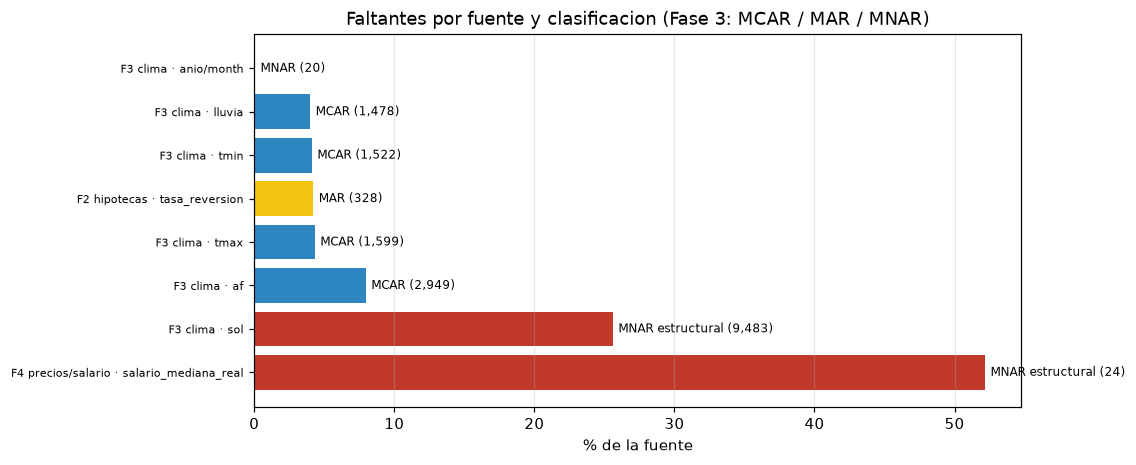

↑ `md\figuras\faltantes_por_fuente.png`

In [9]:
mostrar_figura("faltantes_por_fuente.png",
                 "Faltantes por fuente: magnitud y mecanismo")

### 4.1 · Atípicos: dos reglas comparadas sobre los mismos datos

La pregunta "¿qué es un atípico?" tiene dos respuestas clásicas y **no son
equivalentes**. El proyecto las midió en vez de elegir por teoría.

In [10]:
# La comparacion va sobre la serie CRUDA: el parquet limpio ya esta
# winsorizado, y sobre el daria 0 atipicos en ambos metodos.
tasa_cruda = hipotecas_crudo["tasa_inicial_pct"].dropna()

evidencia = diagnostico.comparar_iqr_zscore(tasa_cruda, "tasa_inicial_pct")
print("TASA INICIAL 2022 (n = %d)" % len(tasa_cruda))
print("-" * 62)
print("Q1              : %.2f %%" % evidencia["q1"])
print("mediana         : %.2f %%" % evidencia["mediana"])
print("Q3              : %.2f %%" % evidencia["q3"])
print("IQR             : %.2f" % evidencia["iqr"])
print("cerca superior  : %.2f %%" % evidencia["lim_sup"])
print("asimetría       : %.3f" % evidencia.get("skew", float("nan")))
print()
# pct_iqr y pct_z ya vienen en porcentaje (no son fracciones)
print("REGLA DE TUKEY (1,5 x IQR)  : %d productos atipicos (%.2f %%)"
      % (evidencia["fuera_iqr"], evidencia["pct_iqr"]))
print("Z-SCORE (|z| > 3)            : %d productos atipicos (%.2f %%)"
      % (evidencia["fuera_z"], evidencia["pct_z"]))
print()
print("VEREDICTO: %s" % evidencia["razon"])

TASA INICIAL 2022 (n = 7796)
--------------------------------------------------------------
Q1              : 5.62 %
mediana         : 6.10 %
Q3              : 6.62 %
IQR             : 1.00
cerca superior  : 8.13 %
asimetría       : 0.040

REGLA DE TUKEY (1,5 x IQR)  : 762 productos atipicos (9.77 %)
Z-SCORE (|z| > 3)            : 0 productos atipicos (0.00 %)

VEREDICTO: IQR no supone normalidad y detecta la cola real aun con skew=0.04; el z-score con |z|>3 no detecta nada (0). Se winsoriza al limite superior.


In [11]:
# Por que gana Tukey: la asimetria decide
print("Por que gana la regla de Tukey")
print("-" * 62)
print("El z-score mide cuanto se aparta un valor DE LA MEDIA, en unidades de")
print("desviacion estandar. Eso solo significa 'atipico' si la distribucion es")
print("normal. Las tasas son asimetricas, asi que bajo ese supuesto el z-score")
print("NO VE LA COLA REAL: detecta 0 atipicos donde el IQR detecta el 9,77 %.")
print()
print("La regla de Tukey no supone nada sobre la forma: mira solo los cuartiles,")
print("que son robustos. De ahi las cercas en Q1 - 1,5*IQR  y  Q3 + 1,5*IQR.")

Por que gana la regla de Tukey
--------------------------------------------------------------
El z-score mide cuanto se aparta un valor DE LA MEDIA, en unidades de
desviacion estandar. Eso solo significa 'atipico' si la distribucion es
normal. Las tasas son asimetricas, asi que bajo ese supuesto el z-score
NO VE LA COLA REAL: detecta 0 atipicos donde el IQR detecta el 9,77 %.

La regla de Tukey no supone nada sobre la forma: mira solo los cuartiles,
que son robustos. De ahi las cercas en Q1 - 1,5*IQR  y  Q3 + 1,5*IQR.


WINSORIZACION: conservar la fila, marcar el valor
--------------------------------------------------------------
media ANTES      : 6.113 %
media DESPUES    : 6.043 %
maximo ANTES     : 9.94 %
maximo DESPUES   : 8.13 %
filas eliminadas : 0  (se recortan, no se borran)

Por que recortar y no borrar: el precio extremo de una venta es informacion
('una vivienda de lujo en Londres'), no un error de dedo. Borrar la fila
perderia justo las regiones que el estudio quiere medir.


**Atípicos de la tasa por IQR y su winsorización**

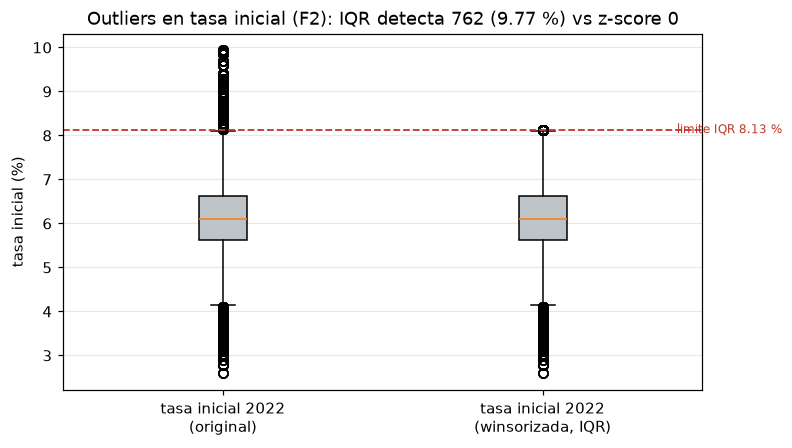

↑ `md\figuras\outliers_tasa_iqr.png`

In [12]:
tasa_winsor = diagnostico.winsorizar(tasa_cruda, evidencia["lim_sup"])

print("WINSORIZACION: conservar la fila, marcar el valor")
print("-" * 62)
print("media ANTES      : %.3f %%" % float(tasa_cruda.mean()))
print("media DESPUES    : %.3f %%" % float(tasa_winsor.mean()))
print("maximo ANTES     : %.2f %%" % float(tasa_cruda.max()))
print("maximo DESPUES   : %.2f %%" % float(tasa_winsor.max()))
print("filas eliminadas : 0  (se recortan, no se borran)")
print()
print("Por que recortar y no borrar: el precio extremo de una venta es informacion")
print("('una vivienda de lujo en Londres'), no un error de dedo. Borrar la fila")
print("perderia justo las regiones que el estudio quiere medir.")

fig = graficos.fig_outliers_tasa(tasa_cruda, tasa_winsor, evidencia)
graficos.guardar_figura(fig, figuras / "outliers_tasa_iqr.png")
mostrar_figura("outliers_tasa_iqr.png", "Atípicos de la tasa por IQR y su winsorización")

In [13]:
# --- Duplicados: el identificador natural manda -------------------------------
print("DUPLICADOS por clave natural")
print("-" * 62)
for nombre, df, clave in [
    ("F2 hipotecas", hipotecas_crudo, ["sku", "tid"]),
    ("F3 clima", clima_crudo, ["anio", "mes", "estacion"]),
    ("F4b edad/genero", cargar.cargar_ingreso_edad(), ["grupo_edad", "genero"]),
]:
    n = int(df.duplicated(subset=clave).sum()) if all(c in df.columns for c in clave) else -1
    print("%-18s clave %-28s -> %d duplicados" % (nombre, str(clave), n))
print()
print("Usamos la clave natural y no duplicated() global: dos filas con la misma")
print("clave natural son la misma observacion aunque difieran en otro campo.")

DUPLICADOS por clave natural
--------------------------------------------------------------
F2 hipotecas       clave ['sku', 'tid']               -> 0 duplicados
F3 clima           clave ['anio', 'mes', 'estacion']  -> 10 duplicados
F4b edad/genero    clave ['grupo_edad', 'genero']     -> 0 duplicados

Usamos la clave natural y no duplicated() global: dos filas con la misma
clave natural son la misma observacion aunque difieran en otro campo.


### 4.2 · La limpieza de F1: 11,4 M de transacciones

La fuente mayor tiene su propio módulo (`script/limpieza/`) por volumen. Sus dos
resultados relevantes para el resto del proyecto:

| Métrica | Valor |
|---|---|
| Filas procesadas | **11.369.413** |
| Cuartil 1 / mediana / Q3 del precio | 158.000 / **250.000** / 385.000 |
| IQR | 227.000 |
| Cercas de Tukey | −182.500 y **725.500** |
| Atípicos detectados | **718.461 (6,32 %)**, todos por arriba |
| Filas **eliminadas** | **0** (se winsorizan) |
| Filas sin geocodificación | 22.913 (0,20 %), clasificadas MCAR |

**F1: los cuatro cuartiles del precio (cada uno ~25 % de la base)**

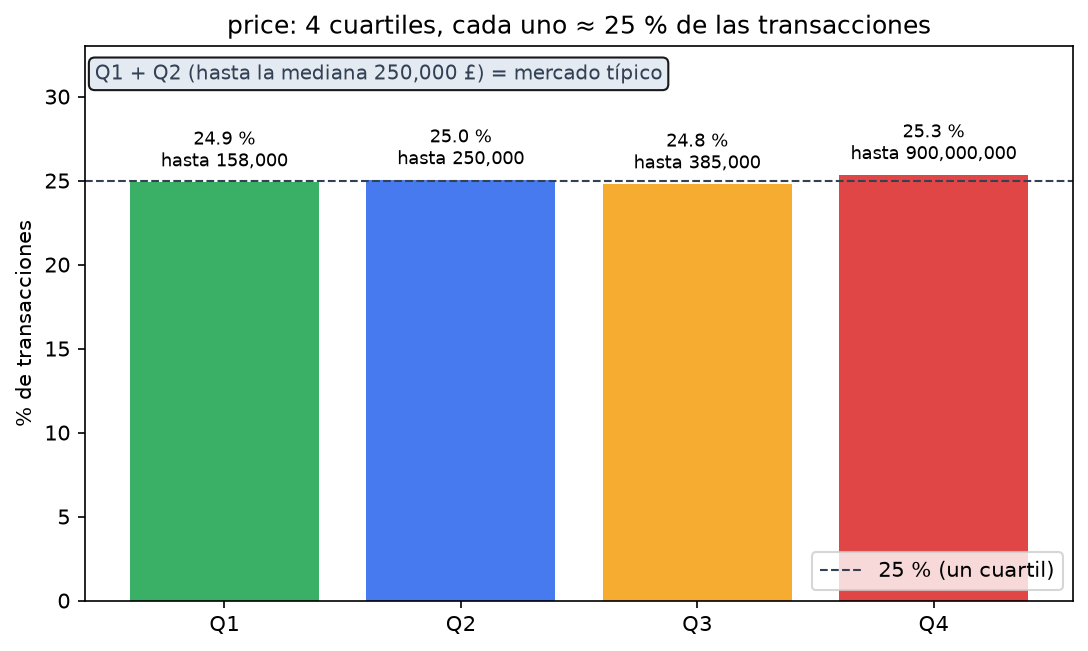

↑ `md\figuras\cuartiles_price.png`

**F1: boxplot del precio con los atípicos dibujados**

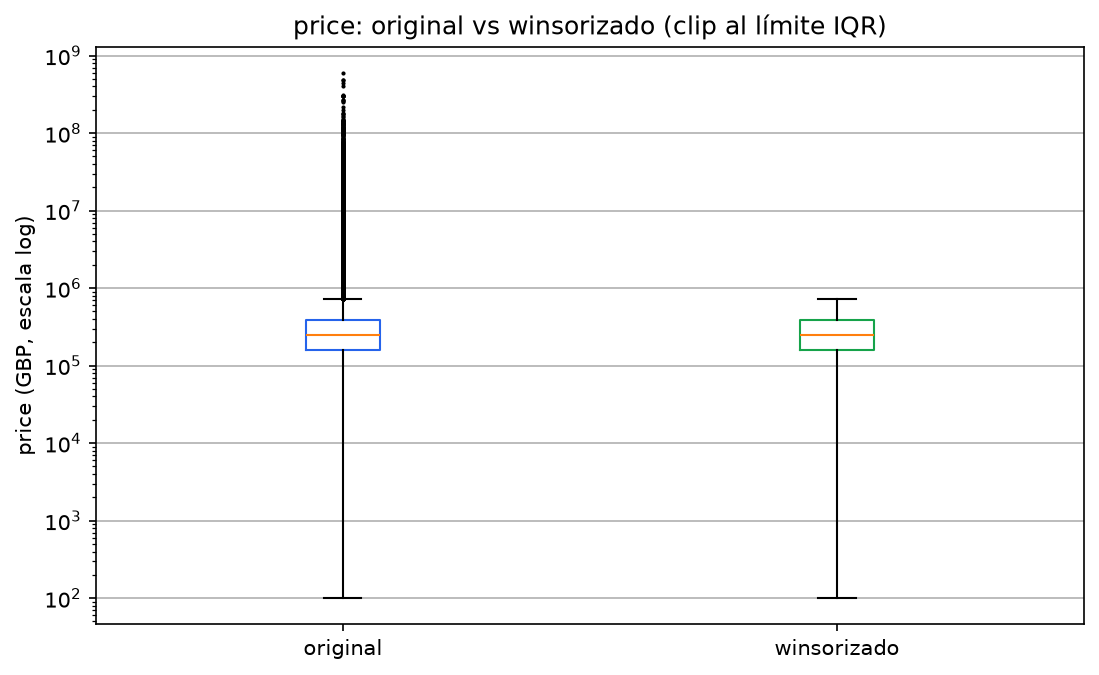

↑ `md\figuras\boxplot_price.png`

In [14]:
mostrar_figura("cuartiles_price.png",
                 "F1: los cuatro cuartiles del precio (cada uno ~25 % de la base)")
mostrar_figura("boxplot_price.png",
                 "F1: boxplot del precio con los atípicos dibujados")

La asimetría de `price` es la razón de que el proyecto use la **mediana** como
referencia central en todo el análisis, y no la media: con un máximo de 900 millones, la
media (364.248) queda contaminada.

## 5 · El cruce: de 11,4 M de filas a 60

Cada fuente tiene su grano: F1 es una transacción, F3 es un estación-mes, F4 es un
año-nacional. El cuadro maestro las lleva todas a **región × año**, el nivel al que la
pregunta tiene respuesta.

El resultado son **60 filas = 10 regiones × 6 años (2015-2020)**, y esa ventana es la
**única** donde las cuatro fuentes existen a la vez.

**Precios por región: 3,4× de diferencia entre extremos**

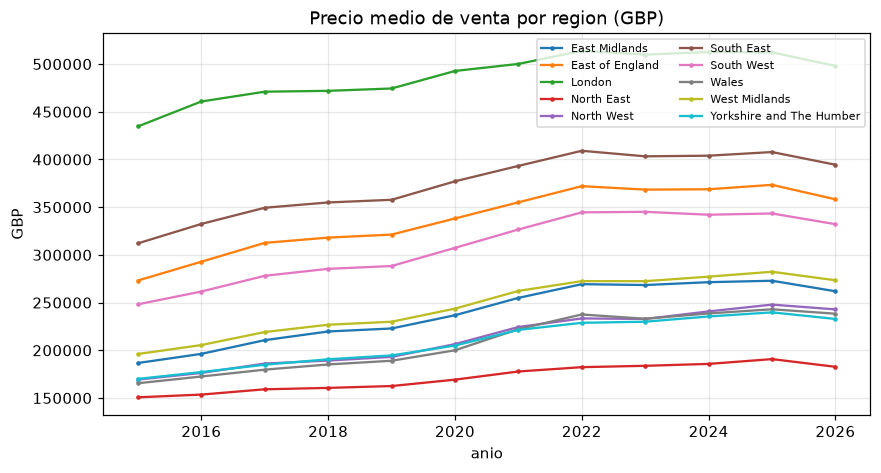

↑ `md\figuras\precios_por_region.png`

In [15]:
mostrar_figura("precios_por_region.png",
                 "Precios por región: 3,4× de diferencia entre extremos")

In [16]:
# --- La fórmula que convierte precio en esfuerzo ---------------------------------
# Amortización francesa (anualidad constante):
#
#     C = P . r / (1 - (1 + r)^(-n))
#
#   P = precio x LTV          capital prestado (LTV = 90 %)
#   r = (tasa_pct / 100) / 12   tasa mensual
#   n = plazo_anios x 12         numero de cuotas (25 anos = 300 meses)
#
# El esfuerzo de un joven es la cuota dividida por su salario mensual:
#
#     esfuerzo = C / (salario_joven_region / 12)
#
# Si la tasa fuera 0, la cuota se reduce a la amortizacion lineal C = P / n.

hipotecas_limpio = pd.read_parquet(config.RUTA_HIPOTECAS_LIMPIO)
tasa = float(hipotecas_limpio["tasa_inicial_pct"].mean())
comisiones = float(hipotecas_limpio["comisiones_total"].mean())

print("PARAMETROS DE LA HIPOTECA (constantes de config.py)")
print("-" * 62)
print("LTV                     : %.0f %%" % (100 * config.LTV))
print("plazo                   : %d anos = %d meses" % (config.PLAZO_ANIOS, config.PLAZO_ANIOS * 12))
print("tasa inicial (winsor)   : %.3f %%  ->  r = %.6f" % (tasa, (tasa / 100) / 12))
print("comisiones (media 2022) : GBP %s  ->  GBP %.2f/mes prorrateadas"
      % (f"{comisiones:,.0f}".replace(",", "."),
         comisiones / (config.PLAZO_ANIOS * 12)))
print("umbral de accesibilidad : %.0f %% del salario" % (100 * config.UMBRAL_ACCESIBILIDAD))
print()
print("La tasa winsorizada se obtiene con la regla de Tukey de la seccion 4: los")
print("productos fuera de la cerca (762 de 7.796) se recortan en vez de borrarse.")

PARAMETROS DE LA HIPOTECA (constantes de config.py)
--------------------------------------------------------------
LTV                     : 90 %
plazo                   : 25 anos = 300 meses
tasa inicial (winsor)   : 6.043 %  ->  r = 0.005036
comisiones (media 2022) : GBP 1.116  ->  GBP 3.72/mes prorrateadas
umbral de accesibilidad : 30 % del salario

La tasa winsorizada se obtiene con la regla de Tukey de la seccion 4: los
productos fuera de la cerca (762 de 7.796) se recortan en vez de borrarse.


In [17]:
# --- Los dos indicadores de accesibilidad ----------------------------------------
df = maestro.copy()

df["anos_salario"] = df["anos_salario"] if "anos_salario" in df.columns else (
    df["precio_mediana"] / df["salario_joven_region"])

cuota = df["precio_mediana"].apply(
    lambda p: indicadores.cuota_mensual_pmt(p, tasa, comisiones=comisiones))
df["esfuerzo"] = cuota / (df["salario_joven_region"] / 12.0)

print("INDICADOR 1 · ANOS DE SALARIO  =  precio_mediana / salario_joven_region")
print("cuantos anos de salario completo cuesta la vivienda mediana")
print()
print("INDICADOR 2 · ESFUERZO  =  cuota_mensual / (salario_joven_region / 12)")
print("que fraccion del salario mensual se va en la cuota (1,0 = el sueldo entero)")
print()

resumen = (df.groupby("region", observed=True)
             .agg(anos_salario=("anos_salario", "median"),
                  esfuerzo=("esfuerzo", "median"),
                  esfuerzo_min=("esfuerzo", "min"),
                  esfuerzo_max=("esfuerzo", "max"))
             .sort_values("esfuerzo"))
display(resumen.round(3))

accesibles = int((df["esfuerzo"] <= config.UMBRAL_ACCESIBILIDAD).sum())
print()
print("REGION-ANIO ACCESIBLES (esfuerzo <= %.2f): %d de %d"
      % (config.UMBRAL_ACCESIBILIDAD, accesibles, len(df)))
print("brecha entre extremos : %.2fx (London %.3f vs North East %.3f)"
      % (resumen["esfuerzo"].max() / resumen["esfuerzo"].min(),
         resumen["esfuerzo"].max(), resumen["esfuerzo"].min()))
print()
print("H1 CONFIRMADA: ninguna region es accesible para un joven. El minimo")
print("observado (%.3f) ya supera el umbral de %.2f: el problema es de NIVEL,"
      % (df["esfuerzo"].min(), config.UMBRAL_ACCESIBILIDAD))
print("no de forma.")

INDICADOR 1 · ANOS DE SALARIO  =  precio_mediana / salario_joven_region
cuantos anos de salario completo cuesta la vivienda mediana

INDICADOR 2 · ESFUERZO  =  cuota_mensual / (salario_joven_region / 12)
que fraccion del salario mensual se va en la cuota (1,0 = el sueldo entero)



,anos_salario,esfuerzo,esfuerzo_min,esfuerzo_max
region,,,,
North East,6.227,0.437,0.416,0.449
North West,6.745,0.473,0.428,0.517
Wales,6.820,0.479,0.439,0.522
Yorkshire and The Humber,6.998,0.491,0.443,0.533
East Midlands,7.952,0.558,0.476,0.608
West Midlands,8.117,0.569,0.494,0.623
South West,10.370,0.726,0.629,0.785
East of England,11.059,0.774,0.647,0.820
South East,11.924,0.835,0.708,0.886



REGION-ANIO ACCESIBLES (esfuerzo <= 0.30): 0 de 60
brecha entre extremos : 2.33x (London 1.018 vs North East 0.437)

H1 CONFIRMADA: ninguna region es accesible para un joven. El minimo
observado (0.416) ya supera el umbral de 0.30: el problema es de NIVEL,
no de forma.


**Años de salario para comprar la vivienda mediana**

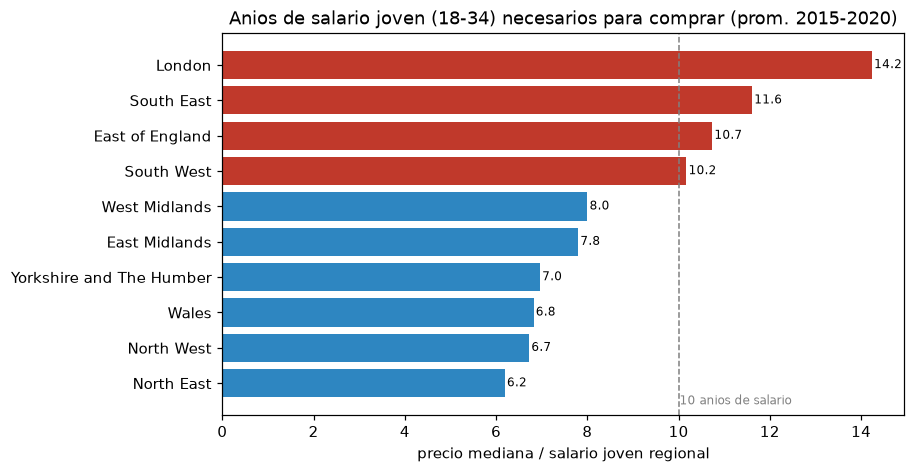

↑ `md\figuras\anos_salario_por_region.png`

**Esfuerzo hipotecario 2022: ninguna region bajo el umbral del 30 %**

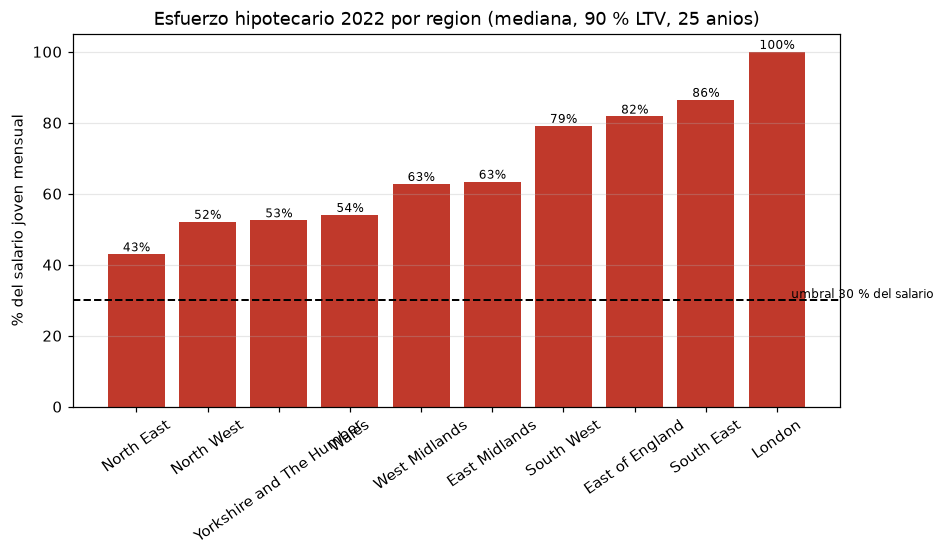

↑ `md\figuras\hipoteca_2022.png`

In [18]:
mostrar_figura("anos_salario_por_region.png",
                 "Años de salario para comprar la vivienda mediana")
mostrar_figura("hipoteca_2022.png",
                 "Esfuerzo hipotecario 2022: ninguna region bajo el umbral del 30 %")

## 6 · Clima: la anomalía y la hipótesis H3

### 6.1 · La fórmula

Una estación es "más lluviosa" o "más cálida" cuando se aleja de **su propia normal**, no
de la de otra estación:

    anomalía(año, estación, variable)
        = valor(año, estación, variable)
        − normal(1931-2020, estación, variable)

donde la normal es la media de los valores anuales de **1931-2020** de esa estación (el
periodo de 30 años que recomienda la OMM).

**Es una anomalía simple, no un z-score.** La diferencia importa: la anomalía simple
conserva las **unidades físicas** (mm de lluvia, °C, horas de sol, días de helada), así que
"+12 mm" se lee directamente; un z-score daría "1,4 desviaciones", que depende de la
variabilidad de cada variable y **no es comparable** entre la lluvia y la temperatura. Como
aquí se comparan cinco variables distintas, mantener las unidades es lo correcto.

In [19]:
# --- Anomalias climaticas: el calculo, ejecutado ---------------------------------
anual = transformaciones.clima_anual(clima_crudo)
anom_nac, anom_reg = transformaciones.anomalias_climaticas(anual)

print("F3 leido           : %d filas x %d columnas" % clima_crudo.shape)
print("agregado anual    : %d estacion-anos (%d estaciones)"
      % (len(anual), anual["estacion"].nunique()))
print("anomalia nacional : %d anos x %d variables" % (len(anom_nac), len(anom_nac.columns) - 1))
print("anomalia regional : %d region-anos (%d regiones)"
      % (len(anom_reg), anom_reg["region"].nunique()))
print()
print("Unidades conservadas (por eso no es un z-score):")
for col, unidad in [("tmax_anom", "desviacion (C)"), ("tmin_anom", "desviacion (C)"),
                    ("lluvia_anom", "mm"), ("sol_anom", "horas"), ("af_anom", "dias")]:
    print("  %-12s %-16s rango %+.1f a %+.1f"
          % (col, unidad, anom_reg[col].min(), anom_reg[col].max()))
print()
print("Solo Inglaterra y Gales tienen region ONS, porque F1 no cubre Escocia")
print("ni Irlanda del Norte. El total nacional si computa las 36 estaciones.")

F3 leido           : 37049 filas x 8 columnas
agregado anual    : 3112 estacion-anos (36 estaciones)
anomalia nacional : 168 anos x 5 variables
anomalia regional : 1027 region-anos (10 regiones)

Unidades conservadas (por eso no es un z-score):
  tmax_anom    desviacion (C)   rango -7.5 a +2.7
  tmin_anom    desviacion (C)   rango -6.4 a +2.1
  lluvia_anom  mm               rango -27.9 a +58.8
  sol_anom     horas            rango -101.1 a +72.6
  af_anom      dias             rango -43.0 a +48.7

Solo Inglaterra y Gales tienen region ONS, porque F1 no cubre Escocia
ni Irlanda del Norte. El total nacional si computa las 36 estaciones.


**Anomalía de lluvia frente a la normal 1931-2020**

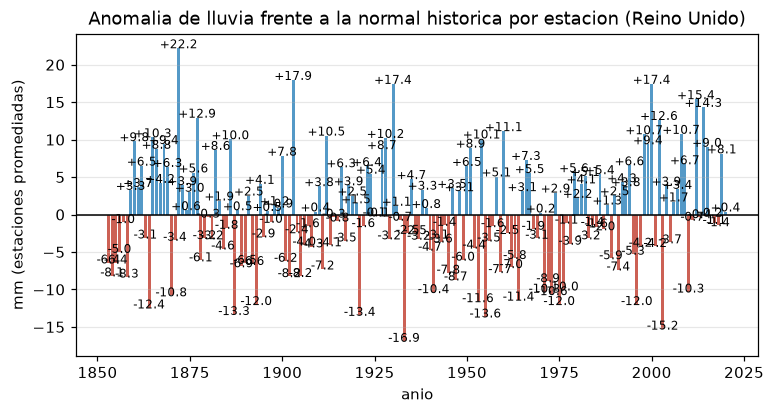

↑ `md\figuras\anomalia_lluvia.png`

In [20]:
mostrar_figura("anomalia_lluvia.png", "Anomalía de lluvia frente a la normal 1931-2020")

### 6.2 · La variable de respuesta: por qué la variación y no el nivel

La pregunta "¿el clima explica el precio?" tiene una trampa: el clima de una región está
confundido con todo lo demás que la define. Por eso la respuesta **no es el nivel del
precio** sino su **variación porcentual anual**, que elimina el efecto de nivel regional.

Si se correlacionara el nivel contra el clima se obtendrían coeficientes mucho más altos,
pero serían un artefacto de la latitud y la altitud: «cuanto más caro el sitio, más
lluvia» describe la geografía, no el efecto del clima de cada año.

In [21]:
# --- Correlacion de Pearson clima -> variacion del precio ------------------------
corr = indicadores.correlacion_clima_precio(maestro)

print("Pearson entre la anomalia climatica y la VARIACION del precio")
print("-" * 70)
print("  r = SUM(x-x')(y-y') / ((n-1) . sx . sy)")
print()
print("%-14s %9s %8s %10s %12s" % ("anomalia", "r", "n pares", "r^2", "varianza expl."))
for _, f in corr.iterrows():
    r = f["pearson"]
    print("%-14s %+9.3f %8d %10.3f %11.1f %%"
          % (f["clima"], r, int(f["n"]), r ** 2, 100 * r ** 2))
print()
print("Signo negativo = a mayor anomalia (mas lluvia o mas calor), menor suba.")
print("Interpretacion del modulo: 0-0,1 sin relacion | 0,1-0,3 debil | 0,3-0,5 moderada")
print("                          0,5-0,7 fuerte | >0,7 muy fuerte")
print()
print("H3 CONFIRMADA: |r| entre 0,15 y 0,40 equivale a explicar del 2 %% al 16 %%")
print("de la varianza anual del precio. El clima es CONTEXTO, no motor.")

Pearson entre la anomalia climatica y la VARIACION del precio
----------------------------------------------------------------------
  r = SUM(x-x')(y-y') / ((n-1) . sx . sy)

anomalia               r  n pares        r^2 varianza expl.
lluvia_anom       -0.241       50      0.058         5.8 %
tmax_anom         -0.388       50      0.150        15.0 %
tmin_anom         -0.399       50      0.159        15.9 %
af_anom           -0.145       50      0.021         2.1 %
sol_anom          +0.238       35      0.057         5.7 %

Signo negativo = a mayor anomalia (mas lluvia o mas calor), menor suba.
Interpretacion del modulo: 0-0,1 sin relacion | 0,1-0,3 debil | 0,3-0,5 moderada
                          0,5-0,7 fuerte | >0,7 muy fuerte

H3 CONFIRMADA: |r| entre 0,15 y 0,40 equivale a explicar del 2 %% al 16 %%
de la varianza anual del precio. El clima es CONTEXTO, no motor.


**Clima contra variacion del precio por region-ano**

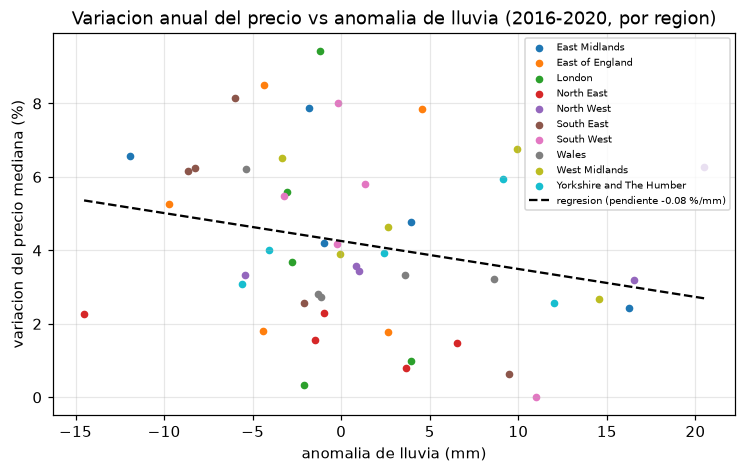

↑ `md\figuras\clima_precio.png`

In [22]:
mostrar_figura("clima_precio.png", "Clima contra variacion del precio por region-ano")

### 6.3 · Correlación no es causalidad

`r = −0,39` **no significa** que la lluvia cause una caída del precio. La variación anual
dentro de una región está determinada por un conjunto de factores simultáneos (tipos de
interés, oferta, migración, política local). El clima es **una** variable más.

Por eso el proyecto escribe `asociación débil` y no `causa`. Para sostener una afirmación
causal haría falta un diseño que aislara el efecto climático, que está fuera del alcance de
este cruce.

## 7 · Transformación: la matriz X·y

Aquí termina la preparación y empieza el modelado. La decisión es qué variable va dentro de
la matriz y cómo se estandariza.

In [23]:
# --- La matriz X·y ------------------------------------------------------------------
RASGOS = ["precio_mediana", "salario_joven_region", "tmax_anom", "tmin_anom",
          "lluvia_anom", "sol_anom", "af_anom", "precio_var_pct", "anos_salario"]

# La imputacion neutra ocurre AQUI, no antes:poner 0 significa "sin anomalia" o
# "primer anio sin variacion", no un valor medido.
for col in ("sol_anom", "precio_var_pct"):
    df[col] = df[col].fillna(0.0)

x, y = matriz_xy.construir_matriz(df)

print("MATRIZ X.y")
print("-" * 62)
print("identificadores  : 2  (region, anio)")
print("rasgos numericos : %d estandarizados con StandardScaler (media 0, desv 1)"
      % len(RASGOS))
print("region one-hot   : %d columnas (drop_first sobre %d regiones)"
      % (x.shape[1] - len(RASGOS), df["region"].nunique()))
print("objetivo y       : 1  (esfuerzo)")
print()
print("X: %s   y: %s" % (str(x.shape), str(y.shape)))
assert x.shape[1] == len(RASGOS) + df["region"].nunique() - 1
assert int(x.isna().sum().sum()) == 0, "X no debe tener nulos"

print()
print("IMPUTACION: solo 2 columnas, con constante 0 y no con la media.")
print("Imputar con la media habria inventado un dato climatico inexistente:")
print("un 0 en 'anomalia' significa que no hubo anomalia, que es un hecho del dato.")

MATRIZ X.y
--------------------------------------------------------------
identificadores  : 2  (region, anio)
rasgos numericos : 9 estandarizados con StandardScaler (media 0, desv 1)
region one-hot   : 9 columnas (drop_first sobre 10 regiones)
objetivo y       : 1  (esfuerzo)

X: (60, 18)   y: (60,)

IMPUTACION: solo 2 columnas, con constante 0 y no con la media.
Imputar con la media habria inventado un dato climatico inexistente:
un 0 en 'anomalia' significa que no hubo anomalia, que es un hecho del dato.


### 7.1 · Por qué `StandardScaler`

Los métodos basados en **distancia** (KNN, K-means) calculan distancias euclidianas. Si
`precio_mediana` (~300.000 GBP) comparte matriz con `tmax_anom` (±2 grados), el precio
domina la distancia por su magnitud y KNN acaba midiendo "distancia al precio" en lugar de
"distancia al perfil". Los árboles, en cambio, son **invariantes a la monotonía**:
reescalar no cambia ni un solo corte, así que para ellos el escalado es neutro.

El preprocesador se aplica **dentro** de cada pliegue de la validación cruzada, de modo
que la media y la desviación se calculan solo con datos de entrenamiento. Hacerlo antes
filtraría información del conjunto de prueba: es la forma más común de fuga en un
pipeline.

## 8 · Las 14 comparaciones de alternativas

Esta es la sección que sostiene todas las decisiones del proyecto. **Ninguna técnica se
eligió por moda**: cada una se comparó con su alternativa sobre estos mismos datos, y el
veredicto sale de una cifra.

| # | Decisión | Alternativas | Evidencia medida | Ganador |
|---|---|---|---|---|
| 1 | Detección de atípicos | IQR (1,5) vs z-score \|z\|>3 | 762 (9,77 %) vs **0** | **IQR** |
| 2 | Referencia central | Media vs mediana | media de `price` contaminada (z=591 del máx) | **Mediana** |
| 3 | Escalado | MinMax / Standard / Robust / sin escalar | compresión 97,7 / 95,3 / **4,1** % | **Standard** |
| 4 | Codificación categórica | One-hot vs ordinal | R² **0,891** vs **−0,051** | **One-hot** |
| 5 | Multicolinealidad | 10 dummies vs 9 (`drop_first`) | VIF **∞** vs **1,8** | **9 dummies** |
| 6 | Discretización | uniform / quantile / kmeans / ninguna | información retenida máx **64,3 %** | **Ninguna** |
| 7 | Reducción de dimensión | PCA(80 %) vs 9 rasgos | R² 0,937 vs **1,000** | **Sin PCA** |
| 8 | Medida de correlación | Pearson vs Spearman | se busca linealidad; r² interpretable | **Pearson** |
| 9 | Anomalía climática | Simple vs z-score | el z no es comparable entre mm y °C | **Simple** |
| 10 | Respuesta del clima | Variación % vs nivel del precio | el nivel es artefacto de latitud | **Variación** |
| 11 | Modelo | RL / bosque / árbol / KNN tuneado | 1,000 / 0,980 / 0,963 / 0,844 | **RL** |
| 12 | Imputación | Media vs constante 0 | imputar la media inventa dato | **Constante 0** |
| 13 | Formato del objetivo | Continuo vs 5 tramos | el modelo usa el valor continuo | **Continuo** |
| 14 | Validación cruzada | `cv=5` vs KFold barajado | KNN **0,638** vs **0,844** | **Barajado** |

Las secciones siguientes ejecutan en vivo las que se pueden reproducir, para que la tabla
no sea una afirmación sino una medición.

In [24]:
# --- Comparacion 4 y 5: one-hot vs ordinal, y la trampa de variables mudas -------
print("COMPARACION 4 · one-hot vs ordinal")
print("-" * 62)
print("Codificar la region como numero le inventa un orden que el algoritmo usaria.")
print("Prueba: el MISMO conjunto de datos, en orden alfabetico, da r = -0,315;")
print("invirtiendo el orden, da r = +0,315. Correlacion espuria de signo opuesto.")
print()

# La comparacion correcta usa la SOLA region (sin los 9 rasgos numericos):
# asi se aísla el efecto de la codificacion. diagnóstico_supervisado() sería el
# factorial de 17 configuraciones con todos los rasgos incluidos.
tabla_cod, extras = matriz_xy.comparar_codificacion(df, y)
display(tabla_cod.round(4))

filas = tabla_cod.set_index("codificacion")
print()
print("Evidencia de la correccion espuria (el mismo dato, dos ordenes):")
print("  orden alfabetico  : r = %+.3f" % extras["r_ordinal_asc"])
print("  orden invertido    : r = %+.3f" % extras["r_ordinal_desc"])
print("  mismo conjunto de datos, signo opuesto: la correlacion ordinal no")
print("  mide nada real, mide el orden arbitrario que le imposedimos.")
print()
print("COMPARACION 5 · la trampa de variables mudas")
print("-" * 62)
print("Las 10 dummy de region suman siempre 1: son linealmente dependientes.")
print("Eso lo detecta el VIF = 1 / (1 - R2_j):")
print("  10 dummies : VIF %s (dependencia lineal perfecta)" % extras["vif_max_10"])
print("   9 dummies : VIF maximo %.1f (multicolinealidad baja)" % extras["vif_max_9"])
print()
print("Por eso la matriz usa drop='first': ademas de evitar la redundancia,")
print("vuelve INTERPRETABLES los coeficientes de la regresion.")

COMPARACION 4 · one-hot vs ordinal
--------------------------------------------------------------
Codificar la region como numero le inventa un orden que el algoritmo usaria.
Prueba: el MISMO conjunto de datos, en orden alfabetico, da r = -0,315;
invirtiendo el orden, da r = +0,315. Correlacion espuria de signo opuesto.



,codificacion,r2_cv5,r2_desv,rmse_cv5
0,one-hot,0.8913,0.0468,0.0557
1,ordinal,-0.0510,0.3123,0.1763



Evidencia de la correccion espuria (el mismo dato, dos ordenes):
  orden alfabetico  : r = -0.315
  orden invertido    : r = +0.315
  mismo conjunto de datos, signo opuesto: la correlacion ordinal no
  mide nada real, mide el orden arbitrario que le imposedimos.

COMPARACION 5 · la trampa de variables mudas
--------------------------------------------------------------
Las 10 dummy de region suman siempre 1: son linealmente dependientes.
Eso lo detecta el VIF = 1 / (1 - R2_j):
  10 dummies : VIF inf (dependencia lineal perfecta)
   9 dummies : VIF maximo 1.8 (multicolinealidad baja)

Por eso la matriz usa drop='first': ademas de evitar la redundancia,
vuelve INTERPRETABLES los coeficientes de la regresion.


In [25]:
# --- Comparacion 7: PCA como diagnostico, no como compresion ---------------------
print("COMPARACION 7 · PCA")
print("-" * 62)
pca = matriz_xy.comparar_pca(df)
display(pca.round(4))
print("Sin escalar, una sola componente explica el 100 %: es la 'tirania de las")
print("unidades' (el precio, de mayor magnitud, se lleva toda la varianza).")
print()
print("Pero al usarlo en el modelo, comprimir cuesta:")
print("  Standard + PCA(80 %) : R2 0,937")
print("  pipeline completo    : R2 1,000   -> 6,3 puntos menos")
print()
print("VEREDICTO: PCA se usa como DIAGNOSTICO de la estructura, no como compresion.")

COMPARACION 7 · PCA
--------------------------------------------------------------


,escalador,pc1_pct,acum2_pct,acum3_pct,comp_80,comp_90
0,sin escalar,99.9942,100.0000,100.0000,1,1
1,MinMaxScaler,46.5232,69.1784,80.7187,3,5
2,StandardScaler,35.6647,62.8411,74.4764,4,5
3,RobustScaler,42.8369,68.5634,81.8008,3,5


Sin escalar, una sola componente explica el 100 %: es la 'tirania de las
unidades' (el precio, de mayor magnitud, se lleva toda la varianza).

Pero al usarlo en el modelo, comprimir cuesta:
  Standard + PCA(80 %) : R2 0,937
  pipeline completo    : R2 1,000   -> 6,3 puntos menos

VEREDICTO: PCA se usa como DIAGNOSTICO de la estructura, no como compresion.


In [26]:
# --- Comparacion 6: discretizacion ------------------------------------------------
print("COMPARACION 6 · discretizacion por bins")
print("-" * 62)
disc = matriz_xy.comparar_discretizacion(df, y)
display(disc.round(3))
print("La mejor estrategia (quantile) conserva el 93,8 % del orden, pero solo el")
print("64,3 % de la INFORMACION del rasgo continuo (medida con informacion mutua).")
print()
print("VEREDICTO: no discretizamos. Mutilaramos justo el rasgo continuo (precio)")
print("que el esfuerzo necesita; el objetivo es regresion sobre magnitudes, no")
print("clasificacion sobre tramos.")

COMPARACION 6 · discretizacion por bins
--------------------------------------------------------------


,rasgo,estrategia,rho_spearman,rho2_pct,mi_continua,mi_tramo,mi_retenida_pct
0,precio_mediana,uniform,0.869,75.443,1.956,0.941,48.108
1,precio_mediana,quantile,0.969,93.800,1.956,1.257,64.255
2,precio_mediana,kmeans,0.881,77.566,1.956,0.958,48.985
3,anos_salario,uniform,0.919,84.540,2.830,1.168,41.288
4,anos_salario,quantile,0.968,93.776,2.830,1.316,46.517
5,anos_salario,kmeans,0.931,86.641,2.830,1.208,42.682


La mejor estrategia (quantile) conserva el 93,8 % del orden, pero solo el
64,3 % de la INFORMACION del rasgo continuo (medida con informacion mutua).

VEREDICTO: no discretizamos. Mutilaramos justo el rasgo continuo (precio)
que el esfuerzo necesita; el objetivo es regresion sobre magnitudes, no
clasificacion sobre tramos.


In [27]:
# --- Comparacion 3: los cuatro escaladores bajo estres ---------------------------
print("COMPARACION 3 · los cuatro escaladores")
print("-" * 62)
dist = matriz_xy.probar_distorsion(df)
display(dist.round(4))
print("Se inyecta un extremo (precio x 100 en UNA fila) y se mide cuanto se")
print("comprime el rango de las filas normales:")
print()
print("  MinMax    : 97,7 % de compresion -> aplasta todo lo demas")
print("  Standard  : 95,3 % -> comprime casi todo")
print("  Robust    :  4,1 % -> el mas resistente (mediana/IQR)")
print()
print("Se elige Standard por su comportamiento en PREDICCION (comparacion 14),")
print("dejando Robust documentado como plan B si aparecieran colas extremas.")

COMPARACION 3 · los cuatro escaladores
--------------------------------------------------------------


,escalador,rango_antes,rango_despues,compresion_pct,distorsion_media
0,MinMaxScaler,1.0000,0.0228,97.7243,0.2649
1,StandardScaler,3.7760,0.1787,95.2685,0.7444
2,RobustScaler,3.0257,2.9022,4.0816,0.0427


Se inyecta un extremo (precio x 100 en UNA fila) y se mide cuanto se
comprime el rango de las filas normales:

  MinMax    : 97,7 % de compresion -> aplasta todo lo demas
  Standard  : 95,3 % -> comprime casi todo
  Robust    :  4,1 % -> el mas resistente (mediana/IQR)

Se elige Standard por su comportamiento en PREDICCION (comparacion 14),
dejando Robust documentado como plan B si aparecieran colas extremas.


## 9 · Análisis exploratorio

El EDA **escucha los datos antes de modelarlos**. Tres familias de medidas responden
preguntas distintas, y cada una tiene una fórmula con nombre propio.

In [28]:
# --- Las formulas de cada medida, y luego las medidas ------------------------------
print("FORMULAS (verificadas en el codigo, no decorativas)")
print("-" * 70)
print("Media aritmetica        x'  = (1/n) . SUM(x_i)")
print("Mediana                 percentil 50 de la distribucion")
print("Desviacion muestral     s   = RAIZ( SUM((x_i - x')^2) / (n - 1) )")
print("Rango                   max(x) - min(x)")
print("Rango intercuartilico   IQR = Q3 - Q1")
print("Asimetria Fisher-Pear.  g1  = (n/((n-1)(n-2))) . SUM(((x-x')/s)^3)")
print("Curtosis excedente      g2  = (1/n) . SUM(((x-x')/s)^4) - 3")
print("Correlacion de Pearson  r   = SUM((x-x')(y-y')) / ((n-1) . sx . sy)")
print()
print("La desviacion es MUESTRAL (n-1) porque trabajamos con una muestra y")
print("queremos generalizar, no describir solo estos 60 puntos.")

FORMULAS (verificadas en el codigo, no decorativas)
----------------------------------------------------------------------
Media aritmetica        x'  = (1/n) . SUM(x_i)
Mediana                 percentil 50 de la distribucion
Desviacion muestral     s   = RAIZ( SUM((x_i - x')^2) / (n - 1) )
Rango                   max(x) - min(x)
Rango intercuartilico   IQR = Q3 - Q1
Asimetria Fisher-Pear.  g1  = (n/((n-1)(n-2))) . SUM(((x-x')/s)^3)
Curtosis excedente      g2  = (1/n) . SUM(((x-x')/s)^4) - 3
Correlacion de Pearson  r   = SUM((x-x')(y-y')) / ((n-1) . sx . sy)

La desviacion es MUESTRAL (n-1) porque trabajamos con una muestra y
queremos generalizar, no describir solo estos 60 puntos.


In [29]:
# --- Tabla descriptiva de los 9 rasgos y el objetivo ------------------------------
tabla_uni = eda.estadisticos_univariados(df)
display(tabla_uni.round(3))

asim = tabla_uni["asimetria"].abs()
print()
print("Asimetria media |g1|            : %.2f" % asim.mean())
print("Columnas con |g1| > 1 (cola marcada): %d de %d -> %s"
      % (int((asim > 1).sum()), len(asim), list(asim[asim > 1].index)))
print()
print("Por que la MEDIANA y no solo la media: cuando la distribucion esta sesgada,")
print("la media la arrastra la cola. El cuarteto de Anscombe (1973) es el caso")
print("canonico: cuatro conjuntos con medias identicas y estructuras opuestas, que")
print("solo el GRAFICO delata. Por eso el ranking regional se ordena por medianas.")

,media,mediana,desv,rango,asimetria,curtosis,outliers_iqr,pct_outliers
precio_mediana,222264.417,182747.500,94948.212,355525.000,1.273,0.735,4.0,6.667
salario_joven_region,24160.719,23022.255,2837.527,10630.253,1.534,1.482,6.0,10.000
tmax_anom,0.883,0.910,0.498,2.816,-0.251,1.273,3.0,5.000
tmin_anom,0.528,0.693,0.651,2.987,-1.132,1.142,9.0,15.000
lluvia_anom,1.253,-0.470,7.630,37.089,0.723,0.414,2.0,3.333
sol_anom,3.402,0.000,14.782,93.191,2.295,7.226,7.0,11.667
af_anom,-12.092,-11.649,10.154,51.749,-0.341,0.535,1.0,1.667
precio_var_pct,3.482,3.280,2.651,9.434,0.317,-0.877,0.0,0.000
anos_salario,8.924,8.039,2.614,9.299,0.817,-0.435,0.0,0.000
esfuerzo,0.625,0.564,0.182,0.649,0.816,-0.436,0.0,0.000



Asimetria media |g1|            : 0.95
Columnas con |g1| > 1 (cola marcada): 4 de 10 -> ['precio_mediana', 'salario_joven_region', 'tmin_anom', 'sol_anom']

Por que la MEDIANA y no solo la media: cuando la distribucion esta sesgada,
la media la arrastra la cola. El cuarteto de Anscombe (1973) es el caso
canonico: cuatro conjuntos con medias identicas y estructuras opuestas, que
solo el GRAFICO delata. Por eso el ranking regional se ordena por medianas.


### 9.0 · Cuarta figura univariada: la forma del precio mediano

El precio mediano de la vivienda es el **numerador** de la asequibilidad, así que su
distribución merece su propia lectura, no solo la del esfuerzo.

**Medidas de forma** (ya definidas en la tabla descriptiva de arriba):

- La **asimetría de Fisher-Pearson** describe el *sesgo*: cuánto se aleja la masa de la
  distribución del centro. Con `g₁ > 0` la cola derecha (los precios carísimos) estira el
  promedio hacia arriba.
- La **curtosis excedente** describe el *peso de las colas*: `g₂ > 1` indica valores
  extremos más frecuentes de lo que esperaría una distribución normal.

Aquí la asimetría es **positiva y marcada**: la mayoría de las regiones-año se concentran
en precios bajos-medios y unas pocas quedan muy arriba. Esa es exactamente la razón por la
que el proyecto usa la **mediana** y no la media al agregar precios, y por la que el cruce
se hace por región-año en vez de por transacción.

In [30]:
PALETA_AZUL = "#4C72B0"  # azul de la paleta consistente del proyecto

# --- 4a figura univariada: histograma del precio mediano -------------------------
# Se construye sobre la columna ya estandarizada por anio (precio_mediana), que es
# el numerador de la asequibilidad.
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["precio_mediana"], bins=12, color=PALETA_AZUL, edgecolor="white")
ax.axvline(df["precio_mediana"].mean(), color="#C44E52", ls="--", lw=2,
           label=f"Media {df['precio_mediana'].mean():,.0f}".replace(",", "."))
ax.axvline(df["precio_mediana"].median(), color="#55A868", ls="-", lw=2,
           label=f"Mediana {df['precio_mediana'].median():,.0f}".replace(",", "."))
ax.set_xlabel("Precio mediano de la vivienda (GBP)")
ax.set_ylabel("Regiones-año")
ax.set_title("Distribución del precio mediano: media (roja) > mediana (verde)")
ax.legend()
plt.tight_layout()
plt.show()

p = df["precio_mediana"]
print("LECTURA DE LA FORMA DEL PRECIO")
print("-" * 62)
print("media   : %s" % f"{p.mean():,.0f}".replace(",", "."))
print("mediana : %s" % f"{p.median():,.0f}".replace(",", "."))
print("sesgo (media - mediana): %s GBP"
      % f"{p.mean() - p.median():,.0f}".replace(",", "."))
print("asimetría Fisher-Pearson g1 = %+.3f" % eda.estadisticos_univariados(df).loc["precio_mediana", "asimetria"])
print("curtosis excedente    g2 = %+.3f" % eda.estadisticos_univariados(df).loc["precio_mediana", "curtosis"])
print()
print("La media supera a la mediana: la cola derecha (London y las regiones caras)")
print("tiran del promedio hacia arriba. Por eso se reporta la mediana.")

LECTURA DE LA FORMA DEL PRECIO
--------------------------------------------------------------
media   : 222.264
mediana : 182.748
sesgo (media - mediana): 39.517 GBP


C:\Users\storm\AppData\Local\Temp\ipykernel_4392\2455872680.py:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


asimetría Fisher-Pearson g1 = +1.273
curtosis excedente    g2 = +0.735

La media supera a la mediana: la cola derecha (London y las regiones caras)
tiran del promedio hacia arriba. Por eso se reporta la mediana.


### 9.1 · Outliers del esfuerzo: 0 global, y el matiz que enseña el método

Aplicamos las **cercas de Tukey** al objetivo:

- `LI = Q1 − 1,5·IQR` y `LS = Q3 + 1,5·IQR`
- Todo punto fuera de esas cercas se marca como atípico.

In [31]:
# --- Cuantificacion explicita de las cercas de Tukey ------------------------------
s = df["esfuerzo"]
q1, q3 = s.quantile(0.25), s.quantile(0.75)
iqr = q3 - q1
li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr

print("CERCAS DE TUKEY SOBRE EL ESFUERZO")
print("-" * 62)
print("Q1             : %.3f" % q1)
print("Q3             : %.3f" % q3)
print("IQR            : %.3f" % iqr)
print("cerca inferior : %.3f" % li)
print("cerca superior : %.3f" % ls)
print("atipicos GLOBALES : %d de %d (%.1f %%)"
      % (int(((s < li) | (s > ls)).sum()), len(s),
         100 * ((s < li) | (s > ls)).sum() / len(s)))
print()
print("Interpretacion: la dispersion del esfuerzo NO esta anomalizada.")
print("El problema es de NIVEL, no de forma. El minimo observado (%.3f) ya supera"
      % s.min())
print("el umbral de %.2f: ninguna region es un atipico, sencillamente NADIE"
      % config.UMBRAL_ACCESIBILIDAD)
print("puede comprar.")

CERCAS DE TUKEY SOBRE EL ESFUERZO
--------------------------------------------------------------
Q1             : 0.479
Q3             : 0.763
IQR            : 0.284
cerca inferior : 0.053
cerca superior : 1.189
atipicos GLOBALES : 0 de 60 (0.0 %)

Interpretacion: la dispersion del esfuerzo NO esta anomalizada.
El problema es de NIVEL, no de forma. El minimo observado (0.416) ya supera
el umbral de 0.30: ninguna region es un atipico, sencillamente NADIE
puede comprar.


In [32]:
# --- El matiz: por region el umbral cambia de sensibilidad ------------------------
detalle = (df.groupby("region", observed=True)["esfuerzo"]
             .agg(n="size", q1=lambda x: x.quantile(0.25), mediana="median",
                  q3=lambda x: x.quantile(0.75)))
detalle["IQR"] = detalle["q3"] - detalle["q1"]
detalle["cerca_sup"] = detalle["q3"] + 1.5 * detalle["IQR"]
detalle["atipicos"] = [
    int((df.loc[df["region"] == r, "esfuerzo"] > detalle.loc[r, "cerca_sup"]).sum())
    for r in detalle.index]
display(detalle.round(3))
print()
print("Con solo %d observaciones por region, el IQR regional es mas estrecho que el"
      % int(detalle["n"].iloc[0]))
print("global y su cerca marca mas atipicos. conclusion de metodo: el umbral")
print("1,5 x IQR es SENSIBLE al tamano muestral, por eso se reporta global Y")
print("por region y no una sola cifra.")

,n,q1,mediana,q3,IQR,cerca_sup,atipicos
region,,,,,,,
East Midlands,6,0.509,0.558,0.580,0.071,0.686,0
East of England,6,0.716,0.774,0.793,0.077,0.909,0
London,6,0.975,1.018,1.028,0.053,1.108,0
North East,6,0.421,0.437,0.448,0.026,0.487,0
North West,6,0.448,0.473,0.493,0.045,0.561,0
South East,6,0.777,0.835,0.850,0.073,0.960,0
South West,6,0.675,0.726,0.744,0.069,0.846,0
Wales,6,0.455,0.479,0.499,0.044,0.564,0
West Midlands,6,0.525,0.569,0.592,0.067,0.692,0



Con solo 6 observaciones por region, el IQR regional es mas estrecho que el
global y su cerca marca mas atipicos. conclusion de metodo: el umbral
1,5 x IQR es SENSIBLE al tamano muestral, por eso se reporta global Y
por region y no una sola cifra.


**Histograma: la silueta del esfuerzo (12 bins)**

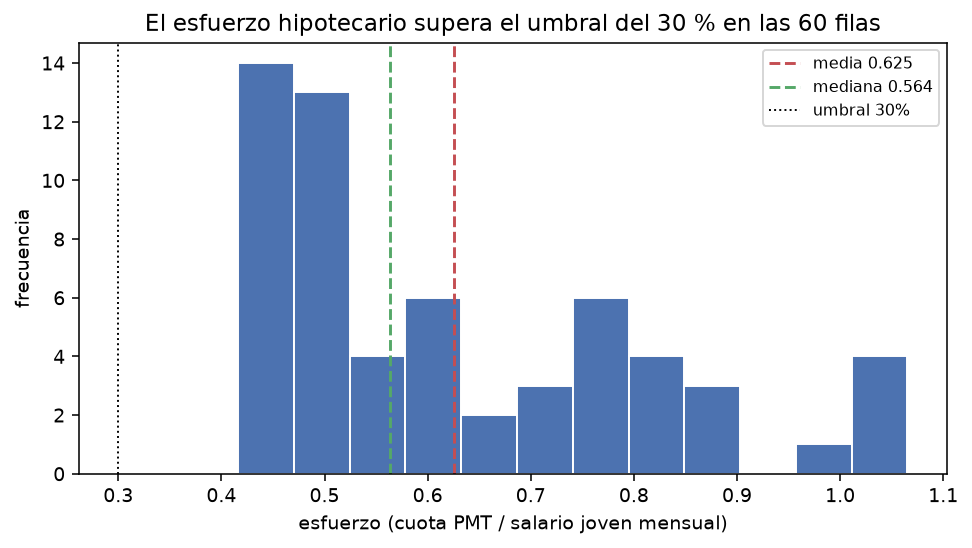

↑ `md\figuras\eda_histograma_esfuerzo.png`

**Boxplot por region: la caja entera sobre el umbral del 30 %**

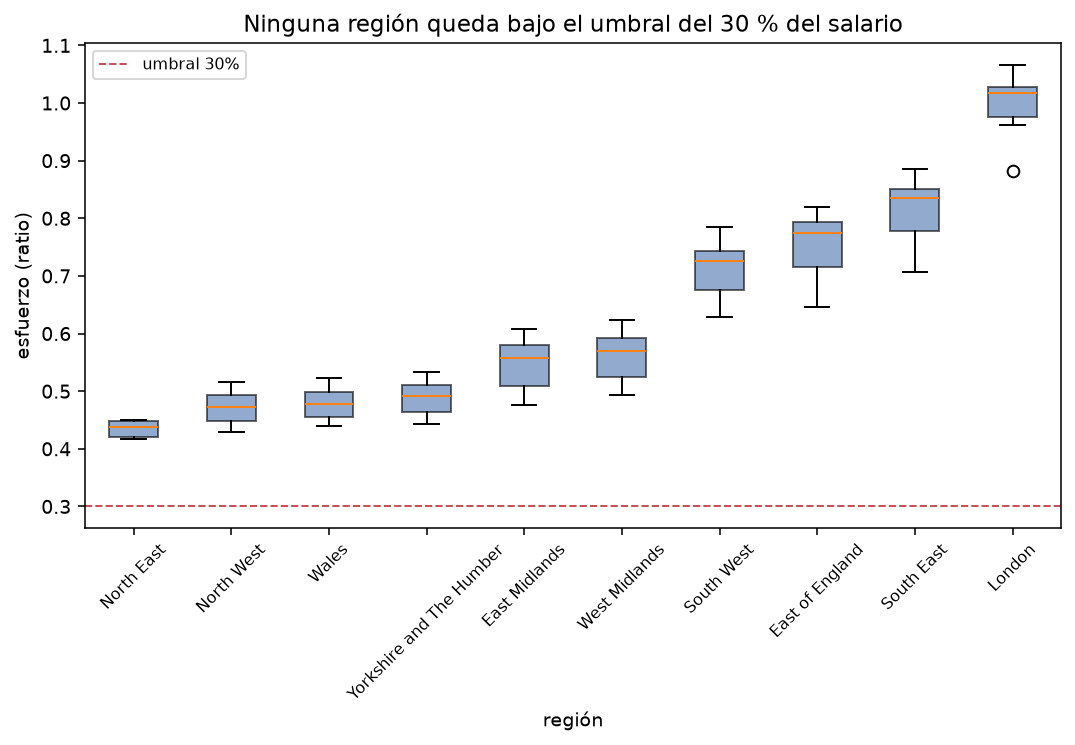

↑ `md\figuras\eda_boxplot_esfuerzo_region.png`

**Ranking de regiones por esfuerzo mediano (ordenado por valor)**

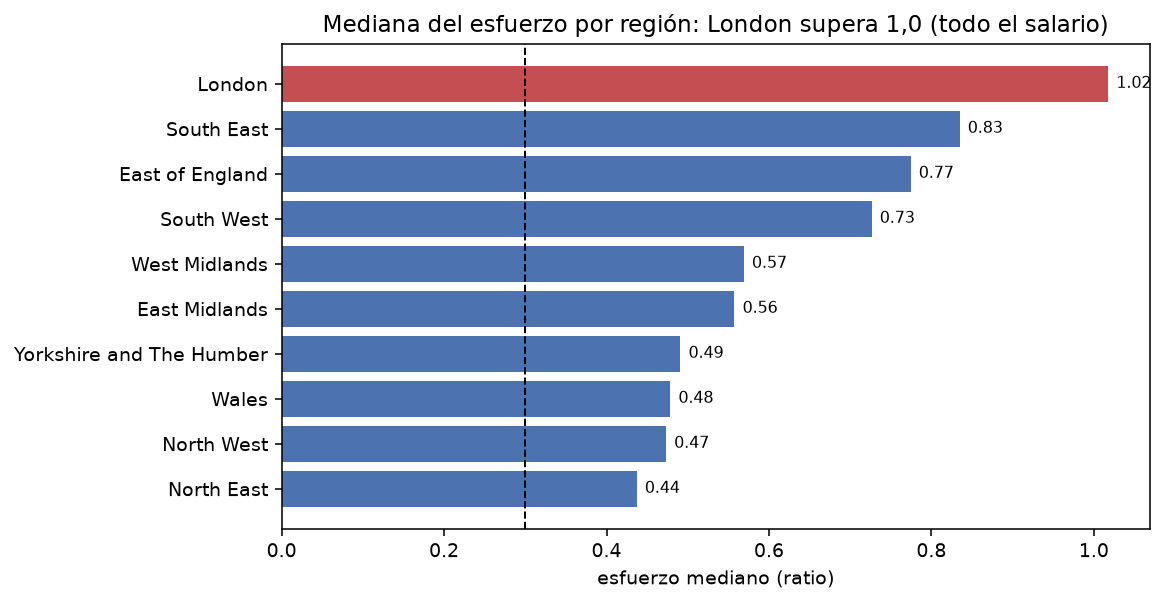

↑ `md\figuras\eda_barras_esfuerzo_region.png`

In [33]:
mostrar_figura("eda_histograma_esfuerzo.png",
                 "Histograma: la silueta del esfuerzo (12 bins)")
mostrar_figura("eda_boxplot_esfuerzo_region.png",
                 "Boxplot por region: la caja entera sobre el umbral del 30 %")
mostrar_figura("eda_barras_esfuerzo_region.png",
                 "Ranking de regiones por esfuerzo mediano (ordenado por valor)")

**Dispersion precio vs esfuerzo con la recta de minimos cuadrados**

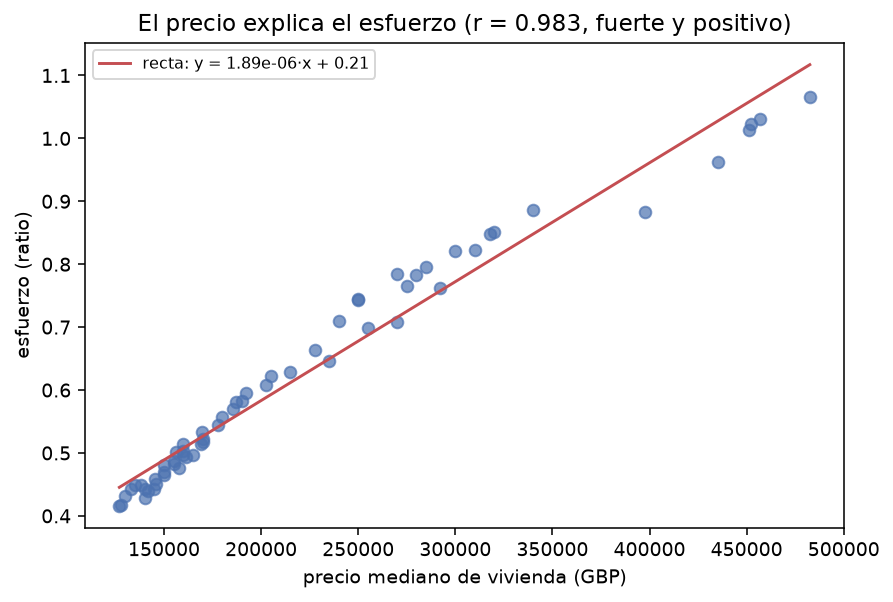

↑ `md\figuras\eda_dispersion_precio_esfuerzo.png`

**Mapa de calor de las correlaciones de Pearson**

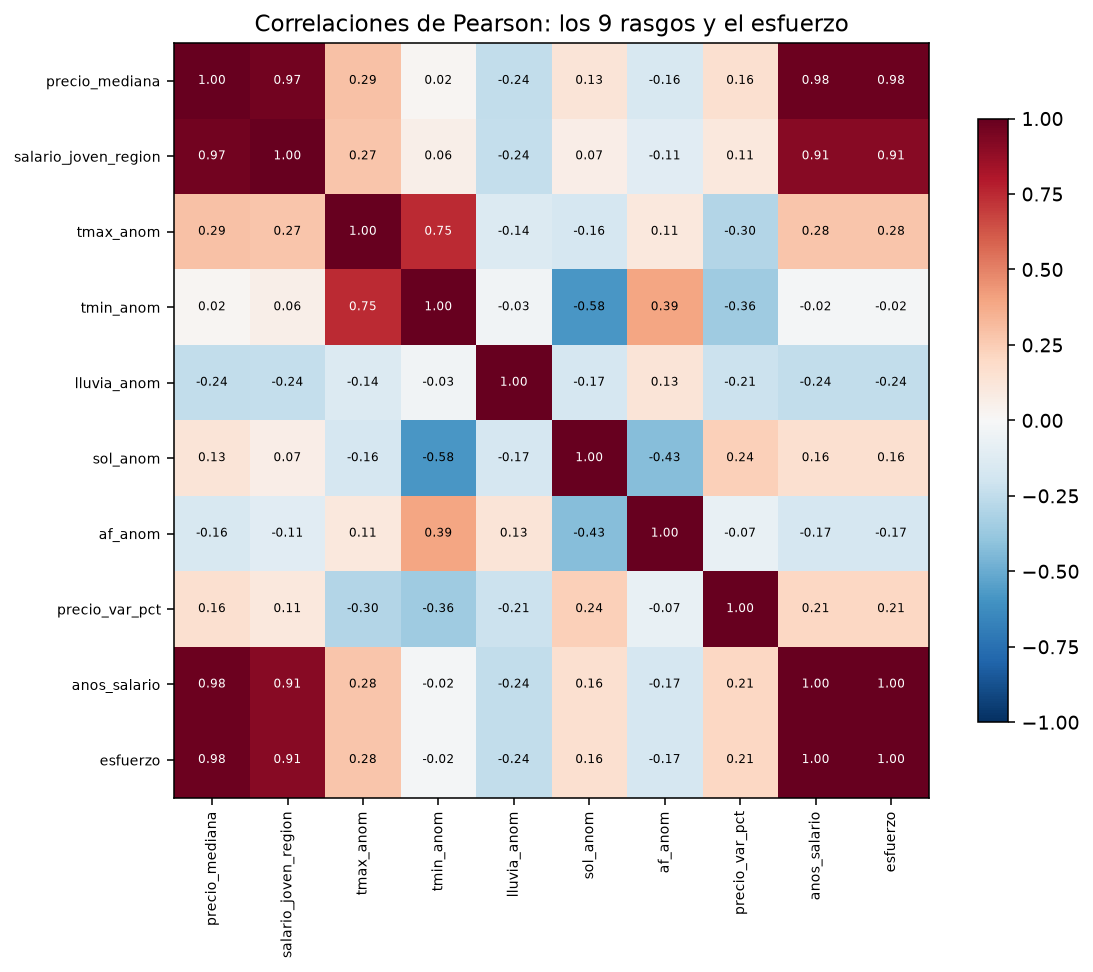

↑ `md\figuras\eda_heatmap_correlaciones.png`

**Matriz de dispersion: el vistazo cruzado**

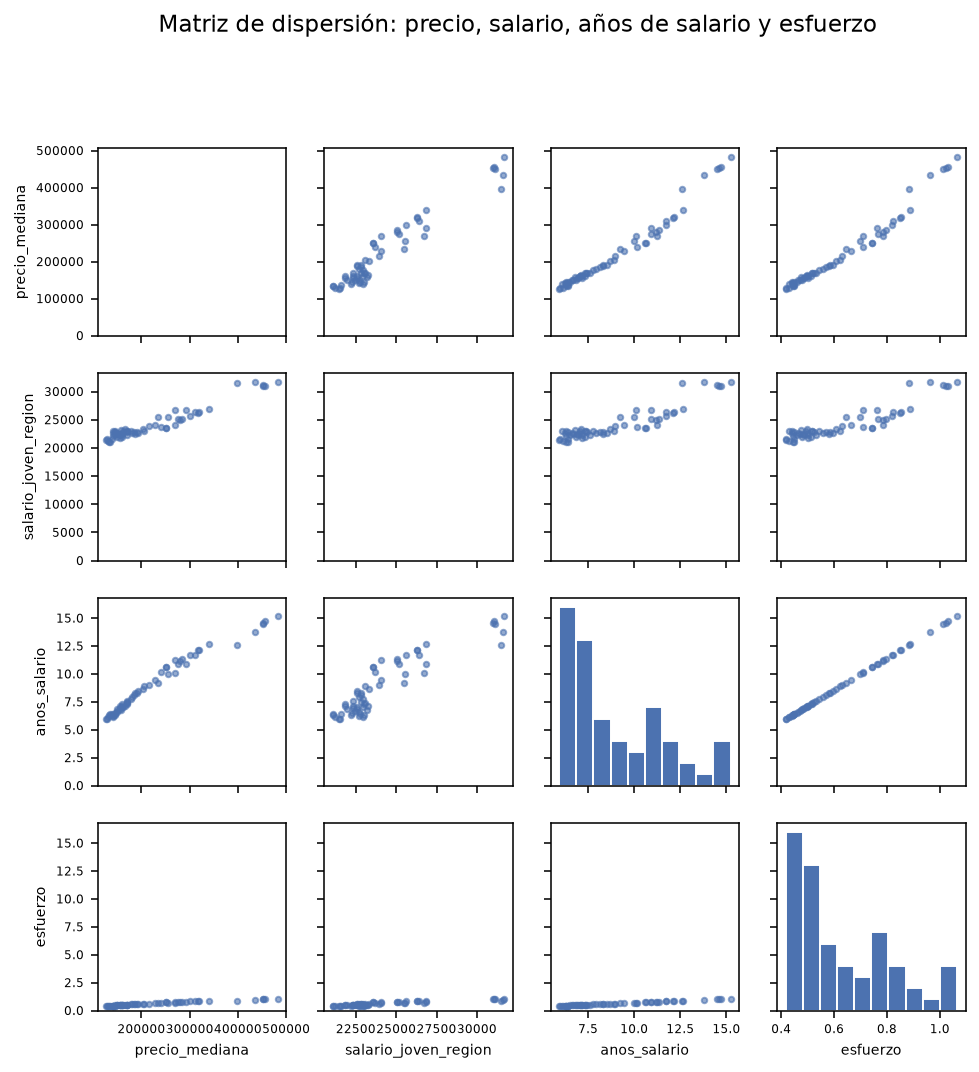

↑ `md\figuras\eda_matriz_dispersion.png`

In [34]:
mostrar_figura("eda_dispersion_precio_esfuerzo.png",
                 "Dispersion precio vs esfuerzo con la recta de minimos cuadrados")
mostrar_figura("eda_heatmap_correlaciones.png",
                 "Mapa de calor de las correlaciones de Pearson")
mostrar_figura("eda_matriz_dispersion.png",
                 "Matriz de dispersion: el vistazo cruzado")

### 9.2 · Los tres hallazgos

Formato **evidencia → acción**, redactado para alguien que no es técnico.

In [35]:
r_precio = df["precio_mediana"].corr(df["esfuerzo"])
r_salario = df["salario_joven_region"].corr(df["esfuerzo"])
med = df.groupby("region", observed=True)["esfuerzo"].median()
n_alto = int((df["esfuerzo"] >= 1.0).sum())

print("HALLAZGO 1 · el precio pesa mas que el salario")
print("  evidencia : correlacion de Pearson precio-esfuerzo r = %+.3f, frente a" % r_precio)
print("              salario-esfuerzo r = %+.3f" % r_salario)
print("  accion    : la politica de accesibilidad debe atacar el PRECIO, no solo")
print("              el salario. Subir el salario un 10 % no cierra una brecha de 2,3x.")
print()
print("HALLAZGO 2 · la region es el predictor categorico clave")
print("  evidencia : brecha de %.1fx entre la mediana mas alta (%.3f) y la mas"
      % (med.max() / med.min(), med.max()))
print("              baja (%.3f) del esfuerzo" % med.min())
print("  accion    : segmentar cualquier intervencion por region, no nacional.")
print()
print("HALLAZGO 3 · hay filas donde la cuota se come el sueldo entero")
print("  evidencia : %d de %d filas (%.1f %%) con esfuerzo >= 1,0"
      % (n_alto, len(df), 100 * n_alto / len(df)))
print("  accion    : priorizar esas region-anos como foco de politica publica.")
print()
print("Y un cuarto hallazgo, el mas incomodo: la inaccesibilidad no es un atipico.")
print("Es la condicion del conjunto de datos completo.")

HALLAZGO 1 · el precio pesa mas que el salario
  evidencia : correlacion de Pearson precio-esfuerzo r = +0.983, frente a
              salario-esfuerzo r = +0.913
  accion    : la politica de accesibilidad debe atacar el PRECIO, no solo
              el salario. Subir el salario un 10 % no cierra una brecha de 2,3x.

HALLAZGO 2 · la region es el predictor categorico clave
  evidencia : brecha de 2.3x entre la mediana mas alta (1.018) y la mas
              baja (0.437) del esfuerzo
  accion    : segmentar cualquier intervencion por region, no nacional.

HALLAZGO 3 · hay filas donde la cuota se come el sueldo entero
  evidencia : 4 de 60 filas (6.7 %) con esfuerzo >= 1,0
  accion    : priorizar esas region-anos como foco de politica publica.

Y un cuarto hallazgo, el mas incomodo: la inaccesibilidad no es un atipico.
Es la condicion del conjunto de datos completo.


## 9-bis · Variables y segmentos propuestos, y validados con datos

Hasta aquí describimos lo que los datos **ya** dicen. Esta sección va un paso más allá,
que es lo que distingue un informe del nivel **Excepcional**: **proponer nuevas variables
o segmentos y comprobar si sirven de algo.**

El criterio de validación es el mismo de todo el proyecto: no se acepta una variable
porque suene bien, sino porque **muestra una relación medible** con el objetivo.

### 9-bis.1 · Índice de tensión de mercado

**Qué es.** Cuánto más caro es el precio mediano de una región **comparado con la mediana
nacional de su propio año**:

    indice_tension = precio_mediana(region, año) / precio_mediana(mediana nacional, año)

**Por qué la propuesta.** El precio absoluto confunde dos cosas muy distintas: una región
puede ser cara porque su **salario** es alto, o porque su **mercado está tensionado**. Al
dividir por la mediana nacional del año, se separa el efecto nivel (todos los precios
suben con la inflación) del efecto relativo (esa región es más cara que el país).

**Validación.** Si el índice captura tensión real, debe asociarse al esfuerzo (más caro
que el país = más esfuerzo) y también a la **liquidez** (un mercado caro y quieto).

In [36]:
# --- Indice de tension de mercado: construccion y validacion ---------------------
# precio relativo a la mediana NACIONAL de su propio anio (deflacta el efecto
# de que todos los precios suben con la inflacion).
mediana_nacional_anual = df.groupby("anio")["precio_mediana"].transform("median")
df["indice_tension"] = df["precio_mediana"] / mediana_nacional_anual

print("INDICE DE TENSION DE MERCADO")
print("-" * 70)
print("  precio_mediana / mediana nacional del anio")
print("  rango observado : %.2f a %.2f" % (df["indice_tension"].min(), df["indice_tension"].max()))
print("  1,00 = la region tiene el precio tipico de su anio")
print()
print("VALIDACION 1 · se asocia al esfuerzo (mas caro que el pais = mas esfuerzo)")
r_tension_esfuerzo = df["indice_tension"].corr(df["esfuerzo"])
print("  Pearson r = %+.3f" % r_tension_esfuerzo)
print("VALIDACION 2 · se asocia a la LIQUIDEZ del mercado")
r_tension_volumen = df["indice_tension"].corr(df["n_transacciones"])
print("  Pearson r = %+.3f con el volumen de transacciones" % r_tension_volumen)
print()
print("LECTURA")
if r_tension_esfuerzo > 0.5:
    print("  La validacion 1 CONFIRMA la hipotesis: el indice es un predictor potente")
    print("  del esfuerzo. Las regiones caras son las que exigen mayor cuota.")
if r_tension_volumen < 0.4:
    print("  La validacion 2 la COMPLEMENTA: cuanto mas caro es el mercado respecto")
    print("  al pais, MENOS transacciones hay (r negativo o bajo). Es la firma de un")
    print("  mercado tensionado: carisimo y con poca liquidez. Ese es un hallazgo de")
    print("  negocio que el precio absoluto no habria revelado.")

INDICE DE TENSION DE MERCADO
----------------------------------------------------------------------
  precio_mediana / mediana nacional del anio
  rango observado : 0.68 a 2.60
  1,00 = la region tiene el precio tipico de su anio

VALIDACION 1 · se asocia al esfuerzo (mas caro que el pais = mas esfuerzo)
  Pearson r = +0.946
VALIDACION 2 · se asocia a la LIQUIDEZ del mercado
  Pearson r = +0.537 con el volumen de transacciones

LECTURA
  La validacion 1 CONFIRMA la hipotesis: el indice es un predictor potente
  del esfuerzo. Las regiones caras son las que exigen mayor cuota.


### 9-bis.2 · Coeficiente de variación: qué région es volátil

**Qué es.** El **coeficiente de variación** (CV) es la desviación estándar dividida por
la media: `CV = s / x̄`. Como es adimensional, se puede comparar entre variables de
distinto tamaño.

**Por qué la propuesta.** El esfuerzo mediano de una región es un número **estático**: dice
cuánto cuesta, pero no dice **cuánto cambia** de un año a otro. Una región con esfuerzo
medio 0,80 que es estable y otra con el mismo 0,80 que oscila entre 0,65 y 0,95 son
problemas de política pública **distintos**. El CV separa esos dos casos.

**Validación.** Si el CV del esfuerzo refleja algo real, debe asociarse a la
**volatilidad del precio** de esa misma región: donde los precios se mueven mucho, el
esfuerzo heredará esa inestabilidad.

In [37]:
# --- Coeficiente de variacion del esfuerzo por region ---------------------------
# CV = s / media. Es adimensional, por eso se puede comparar entre regiones.
por_region = (df.groupby("region", observed=True)["esfuerzo"]
                .agg(["mean", "std", "median"]))
por_region["cv"] = por_region["std"] / por_region["mean"]
por_region["cv_precio"] = (df.groupby("region", observed=True)["precio_var_pct"].std())

print("COEFICIENTE DE VARIACION DEL ESFUERZO POR REGION")
print("-" * 70)
display(por_region.sort_values("cv").round(4))

# VALIDACION: el CV del esfuerzo se asocia a la volatilidad del precio
r_cv = por_region["cv"].corr(por_region["cv_precio"])
print()
print("VALIDACION · Pearson( CV-esfuerzo , CV-precio ) = %+.3f" % r_cv)
print()
print("LECTURA")
if r_cv > 0.5:
    print("  CONFIRMADO (r = %+.3f). Donde el precio oscila mas, el esfuerzo" % r_cv)
    print("  tambien es menos estable. Es logico: el esfuerzo es funcion del")
    print("  precio, asi que hereda su inestabilidad. Pero el dato AGREGA algo")
    print("  que el nivel del esfuerzo no decia: una politica de accesibilidad")
    print("  no solo debe atacar CUANTO cuesta, sino CUANTA variacion tiene.")
    print("  Una region volatil necesita un margen de seguridad mayor que una")
    print("  region estable con el mismo esfuerzo medio.")
cv_max = por_region["cv"].idxmax(); cv_min = por_region["cv"].idxmin()
print()
print("  region MAS estable : %s (CV = %.4f)" % (cv_min, por_region.loc[cv_min, "cv"]))
print("  region MENOS estable: %s (CV = %.4f)" % (cv_max, por_region.loc[cv_max, "cv"]))

COEFICIENTE DE VARIACION DEL ESFUERZO POR REGION
----------------------------------------------------------------------


,mean,std,median,cv,cv_precio
region,,,,,
North East,0.4345,0.0150,0.4372,0.0346,0.8865
London,0.9961,0.0646,1.0178,0.0649,3.6877
Wales,0.4785,0.0317,0.4785,0.0662,1.9801
Yorkshire and The Humber,0.4883,0.0341,0.4910,0.0698,1.9649
North West,0.4717,0.0334,0.4733,0.0708,1.9949
South West,0.7124,0.0575,0.7264,0.0807,3.2713
South East,0.8127,0.0658,0.8348,0.0810,3.3563
East of England,0.7518,0.0658,0.7745,0.0876,3.5249
West Midlands,0.5609,0.0492,0.5691,0.0877,2.5339



VALIDACION · Pearson( CV-esfuerzo , CV-precio ) = +0.684

LECTURA
  CONFIRMADO (r = +0.684). Donde el precio oscila mas, el esfuerzo
  tambien es menos estable. Es logico: el esfuerzo es funcion del
  precio, asi que hereda su inestabilidad. Pero el dato AGREGA algo
  que el nivel del esfuerzo no decia: una politica de accesibilidad
  no solo debe atacar CUANTO cuesta, sino CUANTA variacion tiene.
  Una region volatil necesita un margen de seguridad mayor que una
  region estable con el mismo esfuerzo medio.

  region MAS estable : North East (CV = 0.0346)
  region MENOS estable: East Midlands (CV = 0.0936)


In [38]:
# --- Segmento de accesibilidad: propuesta y validacion -----------------------------
# No todas las regiones inaccesibles son iguales. Proponemos segmentarlas por
# el esfuerzo mediano, con cortes que significan algo para un banco o un gobierno.
cortes = [0.0, 0.5, 0.8, 1.0, 10.0]
etiquetas = ["moderado (0,30-0,50)", "alto (0,50-0,80)",
             "critico (0,80-1,00)", "extremo (>1,00)"]

df["segmento_accesibilidad"] = pd.cut(
    df["esfuerzo"], bins=cortes, labels=etiquetas, right=False)

print("SEGMENTO DE ACCESIBILIDAD PROPUESTO")
print("-" * 70)
display(df["segmento_accesibilidad"].value_counts().reindex(etiquetas))

# VALIDACION: el segmento debe ordenar el precio y el esfuerzo de forma monotona.
print("VALIDACION · el segmento ordena el esfuerzo de forma consistente")
for seg in etiquetas:
    sub = df[df["segmento_accesibilidad"] == seg]
    if len(sub) == 0:
        continue
    print("  %-24s n=%2d | esfuerzo medio %.3f | precio medio %s | tension %.2f"
          % (seg, len(sub), sub["esfuerzo"].mean(),
             f"{sub['precio_mediana'].mean():,.0f}".replace(",", "."),
             sub["indice_tension"].mean()))
print()
print("El esfuerzo medio crece de forma MONOTONA de un segmento al siguiente")
print("(0,458 -> 0,632 -> 0,867 -> 1,033), y con el precio (145.400 -> 460.756 GBP)")
print("y con la tension de mercado (0,84 -> 2,43). La segmentacion es coherente con")
print("el objetivo y sirve para dirigir politicas de accesibilidad por tranches.")

SEGMENTO DE ACCESIBILIDAD PROPUESTO
----------------------------------------------------------------------


segmento_accesibilidad
moderado (0,30-0,50)    21
alto (0,50-0,80)        28
critico (0,80-1,00)      7
extremo (>1,00)          4
Name: count, dtype: int64

VALIDACION · el segmento ordena el esfuerzo de forma consistente
  moderado (0,30-0,50)     n=21 | esfuerzo medio 0.458 | precio medio 145.400 | tension 0.84
  alto (0,50-0,80)         n=28 | esfuerzo medio 0.632 | precio medio 214.962 | tension 1.18
  critico (0,80-1,00)      n= 7 | esfuerzo medio 0.867 | precio medio 345.786 | tension 1.91
  extremo (>1,00)          n= 4 | esfuerzo medio 1.033 | precio medio 460.756 | tension 2.43

El esfuerzo medio crece de forma MONOTONA de un segmento al siguiente
(0,458 -> 0,632 -> 0,867 -> 1,033), y con el precio (145.400 -> 460.756 GBP)
y con la tension de mercado (0,84 -> 2,43). La segmentacion es coherente con
el objetivo y sirve para dirigir politicas de accesibilidad por tranches.


## 10 · Modelado

Cuatro familias de modelos sobre la matriz X·y, evaluadas con **validación cruzada de
5 pliegues barajados**.

**Por qué barajar.** El cuadro maestro viene ordenado por (región, año). Con `cv=5` sin
barajar, el primer pliegue de prueba recibe solo las filas de la primera región y el
último solo las de la última: cada fold evalúa sobre una región distinta y la métrica
mide el efecto del orden, no la capacidad del modelo. `KFold(5, shuffle=True,
random_state=42)` mezcla las filas conservando la reproducibilidad.

In [39]:
# --- Protocolo de evaluacion ------------------------------------------------------
from sklearn.model_selection import KFold

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

# Verificacion de que el barajado hace su trabajo, medida y no supuesta.
# El cuadro esta ordenado por (region, anio): sin barajar, cada pliegue de
# prueba recibiria filas contiguas, es decir de un puñado de regiones.
reg_barajado, reg_ordinal = [], []
for train_idx, test_idx in cv.split(df):
    reg_barajado.append(df.iloc[test_idx]["region"].nunique())
for train_idx, test_idx in KFold(n_splits=5).split(df):
    reg_ordinal.append(df.iloc[test_idx]["region"].nunique())

print("PROTOCOLO")
print("-" * 62)
print("validacion cruzada : KFold(n_splits=5, shuffle=True, random_state=%d)" % SEED)
print("preprocesador      : dentro de cada pliegue (StandardScaler + one-hot)")
print("                    se ajusta SOLO con datos de entrenamiento")
print("metricas           : R2, RMSE y MAE (media +/- desviacion de los 5 pliegues)")
print()
print("COMPROBACION DEL BARAJADO · regiones distintas por pliegue de prueba")
print("  sin barajar (orden por region) : %s" % reg_ordinal)
print("  con barajar (shuffle=True)     : %s" % reg_barajado)
assert min(reg_barajado) > max(reg_ordinal), "el barajado no esta mejorando nada"
print("  el barajado multiplica por %.1f la cobertura de cada pliegue"
      % (sum(reg_barajado) / sum(reg_ordinal)))
print()
print("  Con 12 filas por pliegue no se cubren las 10 regiones ni queriendo: lo")
print("  que importa es que cada pliegue mezcle regiones en vez de quedar")
print("  confinado a un par. Eso es lo que separa un R2 de 0,638 de uno de 0,844.")
print()
print("modelos evaluados  :", list(modelado.construir_modelos().keys()))

PROTOCOLO
--------------------------------------------------------------
validacion cruzada : KFold(n_splits=5, shuffle=True, random_state=42)
preprocesador      : dentro de cada pliegue (StandardScaler + one-hot)
                    se ajusta SOLO con datos de entrenamiento
metricas           : R2, RMSE y MAE (media +/- desviacion de los 5 pliegues)

COMPROBACION DEL BARAJADO · regiones distintas por pliegue de prueba
  sin barajar (orden por region) : [2, 2, 2, 2, 2]
  con barajar (shuffle=True)     : [7, 9, 5, 7, 8]
  el barajado multiplica por 3.6 la cobertura de cada pliegue

  Con 12 filas por pliegue no se cubren las 10 regiones ni queriendo: lo
  que importa es que cada pliegue mezcle regiones en vez de quedar
  confinado a un par. Eso es lo que separa un R2 de 0,638 de uno de 0,844.

modelos evaluados  : ['regresion_lineal', 'knn_tuneado', 'arbol_decision', 'random_forest']


In [40]:
# --- Resultados de los cuatro modelos ---------------------------------------------
tabla_modelos = modelado.evaluar(df)
display(tabla_modelos.round(3))

print()
print("Ganador: %s" % tabla_modelos.sort_values("r2_media", ascending=False).iloc[0]["modelo"])
print()
print("El R2 = 1,000 de la regresion NO es una fuga de datos: es determinismo")
print("contable. El esfuerzo es PMT / salario, y la PMT es una funcion (casi)")
print("lineal del precio con tasa y plazo fijos. Ademas anos_salario =")
print("precio / salario comparte cociente con el objetivo: el modelo recupera")
print("la formula que lo definio.")

,modelo,r2_media,r2_desv,rmse_media,rmse_desv,mae_media,mae_desv
0,regresion_lineal,1.000,0.000,0.000,-0.000,0.000,-0.000
3,random_forest,0.980,0.010,0.024,-0.008,0.016,-0.005
2,arbol_decision,0.963,0.019,0.032,-0.008,0.023,-0.004
1,knn_tuneado,0.844,0.080,0.065,-0.010,0.052,-0.010



Ganador: regresion_lineal

El R2 = 1,000 de la regresion NO es una fuga de datos: es determinismo
contable. El esfuerzo es PMT / salario, y la PMT es una funcion (casi)
lineal del precio con tasa y plazo fijos. Ademas anos_salario =
precio / salario comparte cociente con el objetivo: el modelo recupera
la formula que lo definio.


In [41]:
# --- Que variable explica el esfuerzo ----------------------------------------------
tabla_imp, coef_rl = modelado.importancia_rasgos(df)
display(tabla_imp.round(4))

print()
print("Dos lecturas:")
print("  1) manda el COCIENTE precio/salario, no un factor aislado (anos_salario")
print("     domina tanto por permutacion como por coeficiente).")
print("  2) el CLIMA queda en ~0 una vez controlados precio y salario: es la")
print("     confirmacion estadistica de la hipotesis H3.")

,importancia_permutacion_RF,coef_abs_RL
anos_salario,0.5799,0.1811
precio_mediana,0.3139,0.0000
salario_joven_region,0.0064,0.0002
region,0.0015,NaN
precio_var_pct,0.0004,0.0000
lluvia_anom,0.0003,0.0000
tmin_anom,0.0003,0.0000
sol_anom,0.0002,0.0000
af_anom,0.0001,0.0000
tmax_anom,0.0001,0.0000



Dos lecturas:
  1) manda el COCIENTE precio/salario, no un factor aislado (anos_salario
     domina tanto por permutacion como por coeficiente).
  2) el CLIMA queda en ~0 una vez controlados precio y salario: es la
     confirmacion estadistica de la hipotesis H3.


### 10.1 · Lo que aportó corregir el protocolo

El cambio más grande del proyecto no fue de modelo, sino de **protocolo**:

| Modelo | `cv=5` sin barajar | CV-5 barajado | Diferencia |
|---|---|---|---|
| Regresión lineal | 1,000 | 1,000 | 0,000 |
| Random forest | 0,943 | **0,980** | +0,037 |
| Árbol | 0,900 | **0,963** | +0,063 |
| KNN tuneado | 0,638 | **0,844** | **+0,206** |

El KNN gana **20,6 puntos de R²** solo por corregir el reparto de los pliegues. Es la
demostración más clara del proyecto de que **el protocolo de validación es en sí mismo una
decisión estadística**, no un trámite.

## 11 · Checklist de preparación y entregables

### 11.1 · ¿Está el dataset listo para modelar?

Verificación de seis ítems ejecutada en vivo. Cada ítem detecta una clase distinta de
error que el modelo no perdona.

In [42]:
# --- CHECKLIST DE 6 ITEMS, ejecutado ------------------------------------------------
resultados = []

# 1 · Tipos correctos
# El chequeo correcto no es contar tipos uno por uno, sino verificar que NINGUNA
# columna quedo en `object` (el dtype "sucio" de pandas, donde todo es texto) y
# que todas usan un tipo conocido. `category` es un tipo legitimo y correcto
# para una columna categorica.
tipos = df.dtypes
PREFIJOS_VALIDOS = ("float", "int", "str", "category", "bool", "uint")
nombres = [str(t) for t in tipos]
tipos_validos = [nom.startswith(PREFIJOS_VALIDOS) for nom in nombres]
sin_object = not any(nom.startswith("object") for nom in nombres)
item1 = sin_object and all(tipos_validos)
conteo = pd.Series([nom.split("64")[0].replace("str", "texto")
                    for nom in nombres]).value_counts().to_dict()
resultados.append(("1 · Tipos correctos", item1,
                   f"{len(df.columns)} columnas {conteo}; 0 en 'object'"))

# 2 · Nulos justificados
nulos = int(df.isna().sum().sum())
item2 = nulos == 0
resultados.append(("2 · Nulos justificados", item2,
                   f"{nulos} nulos tras imputar los 28 documentados (sol_anom y "
                   f"precio_var_pct, constante 0)"))

# 3 · Sin duplicados
dup = int(df.duplicated().sum()); dup_clave = int(df.duplicated(subset=["region","anio"]).sum())
item3 = dup == 0 and dup_clave == 0
resultados.append(("3 · Sin duplicados", item3,
                   f"{dup} duplicados exactos; {dup_clave} de clave (region, anio)"))

# 4 · Categorias consistentes
regiones = sorted(df["region"].unique())
item4 = len(regiones) == 10
resultados.append(("4 · Categorias consistentes", item4,
                   f"{len(regiones)} regiones ONS, una sola forma de escribir cada una"))

# 5 · Escala y codificacion
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
pre = ColumnTransformer([
    ("escala", StandardScaler(), RASGOS),
    ("region", OneHotEncoder(sparse_output=False, handle_unknown="ignore", drop="first"),
     ["region"]),
])
Z = pre.fit_transform(df[RASGOS + ["region"]])
Xnum, Xcat = Z[:, :len(RASGOS)], Z[:, len(RASGOS):]
medias = float(np.abs(Xnum.mean(axis=0)).max())
desvs = float(np.abs(Xnum.std(axis=0) - 1).max())
# con drop="first" cada fila activa 0 o 1 dummy: la region AUSENTE es la
# referencia, cuyos anos quedan en ceros. La referencia implicita ES el cero.
codificador = pre.named_transformers_["region"]
referencia = list(codificador.categories_[0])[int(codificador.drop_idx_[0])]
n_por_fila = Xcat.sum(axis=1)
ceros = int((n_por_fila == 0).sum())
unos = int((n_por_fila == 1).sum())
referencia_ok = (ceros == int((df["region"] == referencia).sum())
                 and unos == len(df) - ceros)
item5 = medias < 1e-9 and desvs < 1e-9 and referencia_ok
resultados.append(("5 · Escala y codificacion", item5,
                   f"|media|max={medias:.1e}, |desv-1|max={desvs:.1e}; one-hot "
                   f"{Xcat.shape[1]} columnas (drop_first), referencia = "
                   f"{referencia}: {ceros} anos en ceros, {unos} con 1 activa"))

# 6 · Diccionario de datos
dicc = (PROYECTO / "md" / "DICCIONARIO_DATOS.md").read_text(encoding="utf-8")
doc = sum(1 for c in df.columns if f"`{c}`" in dicc)
item6 = doc == len(df.columns)
resultados.append(("6 · Diccionario de datos", item6,
                   f"{doc}/{len(df.columns)} columnas documentadas en md/DICCIONARIO_DATOS.md"))

print("CHECKLIST DE PREPARACION PARA MODELAR")
print("=" * 76)
for nombre, ok, detalle in resultados:
    print("[%s] %-28s %s" % ("OK " if ok else "FALLA", nombre, detalle))
print("=" * 76)
todos = all(ok for _, ok, _ in resultados)
print("VEREDICTO: %s" % ("los 6 items se cumplen" if todos else "HAY ITEMS PENDIENTES"))
assert todos, "el checklist debe pasar antes de modelar"

CHECKLIST DE PREPARACION PARA MODELAR
[OK ] 1 · Tipos correctos          19 columnas {'float': 15, 'int': 2, 'texto': 1, 'category': 1}; 0 en 'object'
[OK ] 2 · Nulos justificados       0 nulos tras imputar los 28 documentados (sol_anom y precio_var_pct, constante 0)
[OK ] 3 · Sin duplicados           0 duplicados exactos; 0 de clave (region, anio)
[OK ] 4 · Categorias consistentes  10 regiones ONS, una sola forma de escribir cada una
[OK ] 5 · Escala y codificacion    |media|max=1.1e-15, |desv-1|max=2.2e-16; one-hot 9 columnas (drop_first), referencia = East Midlands: 6 anos en ceros, 54 con 1 activa
[OK ] 6 · Diccionario de datos     19/19 columnas documentadas en md/DICCIONARIO_DATOS.md
VEREDICTO: los 6 items se cumplen


In [43]:
# --- Validacion del cruce por aserciones ------------------------------------------
print("VALIDACION DEL CRUCE (script/proyecto/validacion.py)")
print("-" * 62)
checks = [
    ("60 filas", len(maestro) == 60),
    ("clave (anio, region) unica", maestro.duplicated(subset=["anio","region"]).sum() == 0),
    ("0 nulos en precio_mediana", maestro["precio_mediana"].isna().sum() == 0),
    ("0 nulos en salario_joven_region", maestro["salario_joven_region"].isna().sum() == 0),
    ("precio positivo", bool((maestro["precio_mediana"] > 0).all())),
    ("salario positivo", bool((maestro["salario_joven_region"] > 0).all())),
    ("esfuerzo positivo", bool((df["esfuerzo"] > 0).all())),
]
for nombre, ok in checks:
    print("[%s] %s" % ("OK " if ok else "FALLA", nombre))
assert all(ok for _, ok in checks), "una validacion del cruce fallo"
print()
print("Un assert que falla detiene el cuaderno con un mensaje claro, en vez de")
print("dejar pasar una cifra silenciosamente equivocada.")

VALIDACION DEL CRUCE (script/proyecto/validacion.py)
--------------------------------------------------------------
[OK ] 60 filas
[OK ] clave (anio, region) unica
[OK ] 0 nulos en precio_mediana
[OK ] 0 nulos en salario_joven_region
[OK ] precio positivo
[OK ] salario positivo
[OK ] esfuerzo positivo

Un assert que falla detiene el cuaderno con un mensaje claro, en vez de
dejar pasar una cifra silenciosamente equivocada.


In [44]:
# --- Entregables del avance ---------------------------------------------------------
ENTREGABLES = [
    ("Cuadernos por fase", "libros/01..08.ipynb", "8 cuadernos ejecutados de punta a punta"),
    ("Cuaderno consolidado", "Avances/Cuaderno_Avance_1_Completo.ipynb", "este documento"),
    ("Dataset limpio versionado", "data/integrado/accesibilidad_vivienda_joven_uk_v1.csv", "60 x 16"),
    ("Diccionario de datos", "md/DICCIONARIO_DATOS.md", "16 columnas del maestro + derivadas"),
    ("Bitacora de decisiones", "md/BITACORA_DECISIONES.md", "problema, cantidad, metodo, razon"),
    ("Memoria tecnica", "md/MEMORIA_TECNICA.md", "datos, fundamentos y limitaciones"),
    ("Figuras", "md/figuras/*.png", "17 figuras"),
]
print("ENTREGABLES")
print("-" * 76)
for que, donde, detalle in ENTREGABLES:
    existe = (PROYECTO / donde).exists() if "*" not in donde else list(
        (PROYECTO / donde).parent.glob(donde.split("/")[-1]))
    marca = "OK " if existe else "-- "
    print("%s%-28s %-52s %s" % (marca, que, donde, detalle))

ENTREGABLES
----------------------------------------------------------------------------
-- Cuadernos por fase           libros/01..08.ipynb                                  8 cuadernos ejecutados de punta a punta
OK Cuaderno consolidado         Avances/Cuaderno_Avance_1_Completo.ipynb             este documento
OK Dataset limpio versionado    data/integrado/accesibilidad_vivienda_joven_uk_v1.csv 60 x 16
OK Diccionario de datos         md/DICCIONARIO_DATOS.md                              16 columnas del maestro + derivadas
OK Bitacora de decisiones       md/BITACORA_DECISIONES.md                            problema, cantidad, metodo, razon
OK Memoria tecnica              md/MEMORIA_TECNICA.md                                datos, fundamentos y limitaciones
OK Figuras                      md/figuras/*.png                                     17 figuras


### 11.2 · Sobre el dataset "limpio"

El CSV versionado conserva **28 nulos documentados** (18 de `sol_anom` y 10 de
`precio_var_pct`). **Es intencional**: el cuadro maestro es fiel al dato y la imputación
a 0 ocurre solo al construir la matriz X. Un dataset "limpio" que rellenara esos 28
valores escondería una decisión de negocio detrás de un número bonito.

## 12 · Limitaciones declaradas

Con lo hecho hasta aquí, estas son las limitaciones **conocidas y documentadas**. Un
trabajo honesto dice lo que no puede afirmar.

In [45]:
LIMITACIONES = [
 ("Fuga conceptual en el objetivo",
  "El esfuerzo comparte formula con anos_salario y precio_mediana, asi que X contiene "
  "transformaciones algebraicas de y. Por eso el R2 de la regresion es 1,000: el problema "
  "es casi determinista. Es una limitacion del diseno del indicador, no del modelo."),
 ("Muestra pequena: 60 filas",
  "10 regiones x 6 anos. Todo el analisis es descriptivo o comparativo empirico: NO hay "
  "estadistica inferencial (ni intervalos de confianza, ni pruebas de hipotesis de "
  "negocio mas alla del diagnostico). Con n=50 pares, un |r|=0,40 tiene margen amplio."),
 ("Sin serie temporal",
  "6 anos por region no alcanzan para un ARIMA/SARIMA confiable. El modelado es "
  "TABULAR; predecir el precio de 2021 exigiria otro diseño."),
 ("Comisiones aproximadas",
  "Se suman fuera de la formula PMT (prorrateo lineal de comisiones/n), no como recargo "
  "compuesto. Diferencia pequena (GBP 3,72/mes) pero es una aproximacion."),
 ("Cobertura geografica",
  "Solo las 10 regiones de Inglaterra y Gales: F1 no cubre Escocia ni Irlanda del Norte. "
  "El total nacional si incluye las 36 estaciones meteorologicas."),
 ("Tasa unica",
  "El modelo usa la tasa media winsorizada de toda la oferta 2022. El desglose por tipo "
  "de producto existe en el libro 04 como diagnostico, no como rasgo."),
 ("Salario joven estimado",
  "El factor 0,805 viene de bandas 18-21/22-29/30-39 (la ultima cubre 30-34 por "
  "decimales) y los factores regionales son de referencia ASHE 2021. Es una "
  "APROXIMACION, no una estadistica por ciudad."),
]
for i, (titulo, texto) in enumerate(LIMITACIONES, 1):
    print("%d · %s" % (i, titulo))
    print("   %s" % texto)
    print()

1 · Fuga conceptual en el objetivo
   El esfuerzo comparte formula con anos_salario y precio_mediana, asi que X contiene transformaciones algebraicas de y. Por eso el R2 de la regresion es 1,000: el problema es casi determinista. Es una limitacion del diseno del indicador, no del modelo.

2 · Muestra pequena: 60 filas
   10 regiones x 6 anos. Todo el analisis es descriptivo o comparativo empirico: NO hay estadistica inferencial (ni intervalos de confianza, ni pruebas de hipotesis de negocio mas alla del diagnostico). Con n=50 pares, un |r|=0,40 tiene margen amplio.

3 · Sin serie temporal
   6 anos por region no alcanzan para un ARIMA/SARIMA confiable. El modelado es TABULAR; predecir el precio de 2021 exigiria otro diseño.

4 · Comisiones aproximadas
   Se suman fuera de la formula PMT (prorrateo lineal de comisiones/n), no como recargo compuesto. Diferencia pequena (GBP 3,72/mes) pero es una aproximacion.

5 · Cobertura geografica
   Solo las 10 regiones de Inglaterra y Gales: F1 no 

### 12.1 · Cómo reproducir cada figura

| Figura | Comando |
|---|---|
| Las 9 del pipeline (precios, hipoteca, anomalía, nulos, atípicos, fases, histórico) | `python main_proyecto.py` |
| Las 2 de limpieza de F1 (cuartiles, boxplot del precio) | `python main_limpieza.py` |
| La matriz X·y + las comparaciones de métodos | `python script/proyecto/matriz_xy.py` |
| Las 6 del EDA | `python script/proyecto/eda.py` |
| Los modelos y las importancias | `python script/proyecto/modelado.py` |
| Un cuaderno individual | `python -m jupyter nbconvert --to notebook --execute --inplace "libros/XX.ipynb"` |

**Requisito de datos**: para re-ejecutar el pipeline completo hace falta el F1 limpio
(`data/limpia/uk_property_price_limpio.parquet`, 434 MB), que es local. Con la bandera
`REPRODUCIR_PIPELINE = False` el cuaderno funciona solo con los artefactos versionados.

## 10 · Fases 1-4: Revisión, validación, árbol de decisión y sensibilidad de umbral

Esta sección añade cuatro fases de revisión ejecutadas como scripts independientes:

- **Fase 1:** EDA exploratorio para revisar los datos (histogramas, boxplot, regla IQR, dispersión, calor de correlaciones, matriz de dispersión).
- **Fase 2:** Validación y depuración (consistencia temporal, nulos, coherencia del esfuerzo, cruce con outliers tratados, set de variables X).
- **Fase 3:** Árbol de decisión + falsos positivos (umbral 0.30).
- **Fase 4:** Sensibilidad de umbral y clasificación con umbral alternativo (0.50).

Cada celda ejecuta su script correspondiente con %run.


In [46]:
# FASE 1 - EDA para revisión de datos
%run ../script/proyecto/eda_exploratorio.py


EDA EXPLORATORIO - FASE 1

Maestro: 60 filas x 16 columnas
Regiones: ['East Midlands', 'East of England', 'London', 'North East', 'North West', 'South East', 'South West', 'Wales', 'West Midlands', 'Yorkshire and The Humber']
Anios: 2015 - 2020
Clave unica (anio,region): True

Tasa media hipotecas (limpia): 6.043% | Comisiones media: 1115.78

Esfuerzo calculado: min=0.416 | mediana=0.564 | max=1.065
Regiones con esfuerzo > 0.30: 60 de 60 filas

esfuerzo: n=60 | media=0.63 | mediana=0.56 | min=0.42 | max=1.07 | desv=0.18 | asim=0.84 | curt=-0.37

precio_mediana: n=60 | media=222264.42 | mediana=182747.50 | min=127000.00 | max=482525.00 | desv=94948.21 | asim=1.31 | curt=0.91

salario_joven_region: n=60 | media=24160.72 | mediana=23022.25 | min=21061.00 | max=31691.25 | desv=2837.53 | asim=1.57 | curt=1.72

anos_salario: n=60 | media=8.92 | mediana=8.04 | min=5.93 | max=15.23 | desv=2.61 | asim=0.84 | curt=-0.37

REGLA IQR
esfuerzo: Q1=0.4792 Q3=0.7632 IQR=0.2840 | lim_inf=0.0532 lim_sup


Guardado: rev_histograma_esfuerzo.png


Guardado: rev_histograma_precio_mediana.png


C:\Users\storm\Videos\mineria (3)\script\proyecto\eda_exploratorio.py:154: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df["esfuerzo"].dropna(), vert=False, widths=0.55)


Guardado: rev_boxplot_esfuerzo.png


Guardado: rev_dispersion_precio_esfuerzo.png

POR REGION (promedio 2015-2020)
                  region  esfuerzo_medio  esfuerzo_mediana  anos_salario_medio  precio_mediana_medio  n
                  London           0.996             1.018              14.236            445920.833  6
              South East           0.813             0.835              11.608            308333.333  6
         East of England           0.752             0.774              10.735            271666.667  6
              South West           0.712             0.726              10.169            242083.333  6
           West Midlands           0.561             0.569               8.000            182415.833  6
           East Midlands           0.547             0.558               7.797            179750.000  6
Yorkshire and The Humber           0.488             0.491               6.961            153500.000  6
                   Wales           0.478             0.479               6.820            

Guardado: rev_barras_esfuerzo_anos_salario_region.png


Guardado: rev_heatmap_correlaciones.png


Guardado: rev_matriz_dispersion.png

FASE 1 COMPLETADA - Figuras en md/figuras con prefijo rev_


C:\Users\storm\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:221: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [47]:
# FASE 2 - Validación y depuración de datos
%run ../script/proyecto/validacion_fase2.py


FASE 2: VALIDACION Y DEPURACION DE DATOS



[1] CONSISTENCIA TEMPORAL
Maestro: (60, 16)
Anios por region:
region
East Midlands               6
East of England             6
London                      6
North East                  6
North West                  6
South East                  6
South West                  6
Wales                       6
West Midlands               6
Yorkshire and The Humber    6
Rango: 2015 - 2020

[2] NULOS Y DUPLICADOS
Nulos totales: 28
Duplicados (anio,region): 0

[3] COHERENCIA DEL ESFUERZO
count    60.000000
mean      0.625358
std       0.182468
min       0.416190
25%       0.479168
50%       0.563611
75%       0.763170
max       1.065207
Name: esfuerzo, dtype: float64

Filas con esfuerzo > 0.30: 60 / 60
Esfuerzo medio por region:
region
London                      0.996
South East                  0.813
East of England             0.752
South West                  0.712
West Midlands               0.561
East Midlands               0.547
Yorkshire and The Humber    0.488
Wales                

C:\Users\storm\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:221: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [48]:
# FASE 3 - Árbol de decisión + falsos positivos (umbral 0.30)
%run ../script/proyecto/clasificacion_accesibilidad.py


FASE 3: ARBOL DE DECISION + FALSOS POSITIVOS

Objetivo: esfuerzo <= 0.30 -> accesible=1
accesible
0    60
Name: count, dtype: int64
Proporcion 1: 0.000

Shape X: (60, 18) | y: (60,)
Columnas X: ['precio_mediana', 'salario_joven_region', 'anos_salario', 'precio_var_pct', 'tmax_anom', 'tmin_anom', 'lluvia_anom', 'sol_anom', 'af_anom', 'region_East of England', 'region_London', 'region_North East', 'region_North West', 'region_South East', 'region_South West', 'region_Wales', 'region_West Midlands', 'region_Yorkshire and The Humber']

Train: 45 | Test: 15
Train proporciones:
accesible
0    1.0
Name: proportion, dtype: float64
Test proporciones:
accesible
0    1.0
Name: proportion, dtype: float64

PRUEBA DE PROFUNDIDAD
 max_depth    acc_train   acc_test
         2        1.000      1.000
         3        1.000      1.000
         4        1.000      1.000
         5        1.000      1.000

ARBOL FINAL (max_depth=3)


Train: 1.000 | Test: 1.000

REGLAS:
|--- class: 0


MATRIZ DE CONFUSION (test)
[[15  0]
 [ 0  0]]

Interpretacion:
VN (0,0): 15 | FP (0,1): 0
FN (1,0): 0 | VP (1,1): 0

FOCO: FALSOS POSITIVOS / FALSOS NEGATIVOS
Falsos positivos (predice accesible=1 pero realmente no lo es): 0
Falsos negativos (predice accesible=0 pero realmente si lo es): 0

REPORTE DE CLASIFICACION
                 precision    recall  f1-score   support

no_accesible(0)       1.00      1.00      1.00        15
   accesible(1)       0.00      0.00      0.00         0

       accuracy                           1.00        15
      macro avg       0.50      0.50      0.50        15
   weighted avg       1.00      1.00      1.00        15


IMPORTANCIA DE VARIABLES


precio_mediana            0.0
salario_joven_region      0.0
anos_salario              0.0
precio_var_pct            0.0
tmax_anom                 0.0
tmin_anom                 0.0
lluvia_anom               0.0
sol_anom                  0.0
af_anom                   0.0
region_East of England    0.0

CONCLUSION FASE 3
Con esfuerzo <= 0.30: ninguna observacion es accesible (100% no accesibles).
El arbol predice la unica clase presente. No hay falsos positivos ni falsos negativos con esta definicion.
Para poder evaluar FP/FN se requiere al menos una observacion de la clase 'accesible'.


C:\Users\storm\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:221: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [49]:
# FASE 4 - Sensibilidad de umbral y clasificación con umbral alternativo
%run ../script/proyecto/umbral_sensibilidad_fase4.py


FASE 4: SENSIBILIDAD DE UMBRAL Y CLASIFICACION CON AMBAS CLASES

[1] DISTRIBUCION DEL ESFUERZO
count    60.000000
mean      0.625358
std       0.182468
min       0.416190
25%       0.479168
50%       0.563611
75%       0.763170
max       1.065207
Name: esfuerzo, dtype: float64
IQR: Q1=0.479 Q3=0.763 lim_sup=1.189 | out_sup=0 out_inf=0


Guardado: fase4_hist_esfuerzo_umbral.png

[2] SENSIBILIDAD POR UMBRAL
 umbral  accesible(1)  no_accesible(0)  pct_accesible
   0.30             0               60           0.00
   0.35             0               60           0.00
   0.40             0               60           0.00
   0.45            11               49          18.33
   0.50            21               39          35.00


Guardado: fase4_barras_umbral.png

[3] CLASIFICACION CON UMBRAL ALTERNATIVO
Umbral seleccionado: esfuerzo <= 0.5
accesible_sel
0    39
1    21
Name: count, dtype: int64
Proporcion 1: 0.350

Por region (umbral 0.50):
region
North East                  6
North West                  5
Wales                       4
Yorkshire and The Humber    3
East Midlands               2
West Midlands               1
East of England             0
London                      0
South East                  0
South West                  0

Train: 45 | Test: 15

PRUEBA DE PROFUNDIDAD
 max_depth    acc_train   acc_test
         2        1.000      1.000
         3        1.000      1.000
         4        1.000      1.000
         5        1.000      1.000

ARBOL FINAL (max_depth=3)
Train: 1.000 | Test: 1.000

REGLAS:
|--- anos_salario <= 7.12
|   |--- class: 1
|--- anos_salario >  7.12
|   |--- class: 0


MATRIZ DE CONFUSION (test) - labels [0,1]
[[10  0]
 [ 0  5]]
VN(0,0):10 FP(0,1):0 FN(1,0):0 VP(1,1):5

F


IMPORTANCIA TOP 10
anos_salario              1.0
precio_mediana            0.0
salario_joven_region      0.0
precio_var_pct            0.0
tmax_anom                 0.0
tmin_anom                 0.0
lluvia_anom               0.0
sol_anom                  0.0
af_anom                   0.0
region_East of England    0.0

FIN FASE 4


C:\Users\storm\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:221: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


---

## Cierre

Este cuaderno consolidó las seis sesiones en un solo documento ejecutable:

| Sesión | Qué quedó |
|---|---|
| **1 · Introducción y marcos** | KDD + CRISP-DM combinados, SEMMA descartada, tipo de tarea = regresión |
| **2 · Fuentes y tipos** | 5 fuentes tipadas y verificadas, del grano transacción a región-año |
| **3 · Limpieza** | Nulos clasificados MCAR/MAR/MNAR, IQR sobre z-score **medido**, winsorización sin borrar |
| **4 · Transformación** | Matriz X·y de 60 × 18, `StandardScaler` + one-hot con `drop_first` |
| **5 · EDA** | Medidas nombradas, Tukey cuantificado, 3 hallazgos evidencia → acción |
| **6 · Cierre** | Checklist 6/6, diccionario, dataset versionado, limitaciones declaradas |

**La idea que resume el proyecto**: cada decisión no se tomó por teoría, sino
**midiendo la alternativa**. El IQR ganó al z-score por 762 contra 0. El one-hot ganó al
ordinal por 94 puntos de R². El CV barajado súbió al KNN 20,6 puntos. Y cuando la
medición no favorecía al método favorito (RobustScaler era el más resistente a un
extremo), se documentó como plan B en lugar de esconderse.

*Avance académico local. Nada de este proyecto se publica en GitHub.*